# Mercedes-Benz Greener Manufacturing – EDA and modeling

**Goal:** predict the test bench time `y` (seconds) of a car from its options; compare our R² with the Kaggle winners (≈ 0.55) and with the best possible R² from hypothesis H2 (D12, D13, D15).

**Data:** `data/train.csv` (4,209 cars × 378 columns: `ID`, `y`, 8 text columns, 368 0/1 columns). Kept out of git (D6).

## Full step overview
| Section | Plan | Step | Title |
|---|---|---|---|
| 1 Setup & data | M1.3 (setup part) | 1 | Imports, load data/train.csv, shape check (4,209 × 378) |
| 2 H2 – same car, same time? | M1.3 (H2) | 2 | H2.1 Configuration key: all 376 option columns (X0 … X385) combined into one key per car |
| | | 3 | H2.2 Groups of identical configurations (≥ 2 cars): number of groups, number of cars in them |
| | | 4 | H2.3 Spread of `y` inside each group: small summary table + ONE plot (y per group, 15 biggest groups) |
| | | 5 | H2.4 Best possible R² = 1 − (pooled variance of `y` inside groups) / (variance of `y` over all train cars); also shown without the 265 s car |
| | | 6 | H2.5 Reading: compare with Kaggle winners ≈ 0.55; limitation if few duplicates |
| 3 Target y and the 265 s car | M1.4 | 7 | Distribution of `y`: summary + ONE histogram (one smooth curve or several peaks?) |
| | | 8 | The unusual test times: 10 longest tests, cars above 1.5 × IQR and 3 × IQR; where does the 265 s car stand? |
| | | 9 | Keep or drop the 265 s car – proposal (effect on mean, sd, H2 limit); no data removed |
| 4 The text columns | M1.5 | 10 | Levels per text column: distinct values, rare values (< 1 % = fewer than 43 cars), top 3 values (one table) |
| | | 11 | `y` per X0 value: median and count; do X0 values match the peaks of Step 7? Strongest other text column (number only); ONE box plot |
| | | 12 | Values only in test.csv: per text column, how many test cars they affect; encoding proposal for M2 (→ decided: D25) |
| 5 The 0/1 option columns | M1.6 | 13 | Constant columns: 0/1 columns where all cars have the same value; columns where ≤ 42 cars (< 1 %) differ |
| | | 14 | Duplicate columns: groups of identical 0/1 columns, how many columns could be left out, 10 biggest groups |
| | | 15 | Link to `y` (H3): share of `y` differences explained per 0/1 column (group-mean R²), top 10 + ONE bar chart (top 15); keep/drop proposal for M2.0 (→ decided: D27) |
| 6 EDA summary | M1.7 | 16 | EDA summary: X0 alone vs X0 + each top-10 0/1 column (in-sample R², no plot) + one summary table of all findings with their decision IDs |
| 7 Baseline | M2 (2.0–2.5) | 17–22 | Sect. 7 – M2 – Steps 17–22: data preparation, validation setup, rule baselines, Ridge, score table (rebuilds notebook 05 Steps 1–4 step by step, D31); final X0 table for documentation (D35) |
| 8 Three algorithms | M3.1 | 23–25 | Sect. 8 – M3.1 – Steps 23–25: Random Forest, XGBoost, comparison of all models with Ridge and the baselines (D33) |
| 9 Error analysis | M3.2 | 26–27 | Sect. 9 – M3.2 – Steps 26–27: errors per car and per X0 code of the preferred model 20a Ridge X0 only (D40, D41) |
| 10 Kaggle submission | M3.3 | 28 | Sect. 10 – M3.3 – Step 28: final model 20a Ridge X0 only fitted on all 4,208 cars, predictions for all test cars written to `data/submission_ridge_x0_v1.csv` (D43, D45) |
| 11 Long tests | D61 | 29 | Sect. 11 – D61 – Step 29: can long tests (y > 136.30 s) be predicted from the configuration? Long tests per X0 code, out-of-fold flag test (X0 rules, logistic regression), buffer seconds, twins of long-test cars (D60, D61) |

Source: handovers 09 (D16), 10, 11 (D20), 12 (D26), 13 (D27), 16 (D31), 17 (D33), 18 (D35), 20 (D41) and 21 (D45), details in `my_notes/framing_h2_v2.md`. Each step is run on its own with "do step k".

## Section 1 (plan M1.3, setup part): Setup & data

**Section 1 (Setup & data) – Steps overview: load the training data and check it is complete**

| Step | Title | What it does | Source |
|---|---|---|---|
| 1 | Imports, load data/train.csv, shape check | Imports pandas/numpy/plotting, reads `data/train.csv`, checks the shape is 4,209 × 378 | Handover 09, step overview |

### Step 1: Imports, load data/train.csv, shape check

We load the training data (cars with known test time `y`) and check that it is complete before any analysis. Test data is not used in Sections 1–2.

In [1]:
# Section 1, Step 1: Imports, load data/train.csv, shape check
# Uses: data/train.csv from the Kaggle download, handover 02
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Chart colours, defined once for all plots (Steps 4, 7, 11, 15, 21, 25, 27); label_grey = value and tick labels
blue, blue_light, blue_dark = "#2a78d6", "#9ec5f0", "#14457f"
ink, muted, grid, label_grey = "#0b0b0b", "#898781", "#e1e0d9", "#52514e"

train = pd.read_csv("data/train.csv")

# Expected size from the download check (handover 06): 4,209 cars x 378 columns
assert train.shape == (4209, 378), f"unexpected shape {train.shape} - check data/train.csv"

text_cols = train.select_dtypes(include="str").columns.tolist()          # car options written as letters
binary_cols = [c for c in train.columns if c not in ["ID", "y"] + text_cols]  # car options as 0/1

print("Shape:", train.shape)
print("Text columns:", len(text_cols), text_cols)
print("0/1 columns:", len(binary_cols), "| only 0 and 1:", bool(train[binary_cols].isin([0, 1]).all().all()))
print("Option columns in total:", len(text_cols) + len(binary_cols))
print("Missing values:", int(train.isna().sum().sum()))
print("y (seconds): min", train["y"].min(), "| median", train["y"].median(), "| max", train["y"].max())

Shape: (4209, 378)
Text columns: 8 ['X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X8']
0/1 columns: 368 | only 0 and 1: True
Option columns in total: 376
Missing values: 0
y (seconds): min 72.11 | median 99.15 | max 265.32


**Step 1 – reading the result**

| Check | Result |
|---|---|
| Shape | 4,209 cars × 378 columns (as expected) |
| Text columns | 8: X0, X1, X2, X3, X4, X5, X6, X8 |
| 0/1 columns | 368 (all contain only 0 and 1) |
| Option columns in total | 376 = 8 text + 368 0/1 (used as the configuration key in Step 2) |
| Missing values | 0 |
| `y` (seconds) | min 72.11 · median 99.15 · max 265.32 |

In simple words: the data is complete and clean, so we can start H2 directly. The 265 s car stands far above the median of 99 s; it is handled in Step 5 (with and without it) and in M1.4 (H5).

Own decision: text columns are found by data type (text = letters), all other columns except `ID` and `y` count as 0/1 options, because that matches the download check (8 + 368) and needs no hard-coded column list.

## Section 2 (plan M1.3, H2): H2 – same car, same time?

**Section 2 (H2 – same car, same time?) – Steps overview: find out how much of the test time any model can explain at best (train data only)**

| Step | Title | What it does | Source |
|---|---|---|---|
| 2 | H2.1 Configuration key | Combines all 376 option columns (X0 … X385) into one key per car | framing_h2_v2.md, H2.1 |
| 3 | H2.2 Groups of identical configurations | Finds keys shared by ≥ 2 cars: number of groups, number of cars in them | framing_h2_v2.md, H2.2 |
| 4 | H2.3 Spread of `y` inside each group | Small summary table + one plot (y per group, 15 biggest groups) | framing_h2_v2.md, H2.3 |
| 5 | H2.4 Best possible R² | 1 − (pooled variance inside groups) / (variance over all train cars); also without the 265 s car | framing_h2_v2.md, H2.4 |
| 6 | H2.5 Reading the result | Compares with the Kaggle winners ≈ 0.55; notes the limitation if there are few duplicates | framing_h2_v2.md, H2.5 |

### Step 2: H2.1 Configuration key

To answer "does the same car always need the same test time?", we first need to know which cars are *the same*. We combine all 376 option columns of a car into one text key; two cars with the same key have exactly the same configuration.

In [2]:
# Section 2, Step 2: H2.1 Configuration key
# Uses: train, text_cols, binary_cols from Step 1
option_cols = text_cols + binary_cols  # all 376 option columns (X0 ... X385)

# One key per car: all option values written one after another, e.g. "k|v|at|...|0|1|0"
config_key = train[option_cols].astype(str).agg("|".join, axis=1)

# Short number per distinct key (easier to read than the long text key); train itself stays unchanged
config_id = pd.Series(pd.factorize(config_key)[0], index=train.index, name="config_id")

print("Option columns in the key:", len(option_cols))
print("Cars:", len(train))
print("Distinct configuration keys:", config_key.nunique())
print("Key length (characters):", config_key.str.len().min(), "to", config_key.str.len().max())

Option columns in the key: 376
Cars: 4209
Distinct configuration keys: 3911
Key length (characters): 751 to 755


**Step 2 – reading the result**

| Check | Result |
|---|---|
| Option columns in the key | 376 (8 text + 368 0/1) |
| Cars | 4,209 |
| Distinct configuration keys | 3,911 |
| Cars that repeat an earlier configuration | 4,209 − 3,911 = 298 |

In simple words: most cars are unique, but 298 cars have the exact same options as another car in the data. These repeats are what H2 needs. Step 3 counts how many groups they form and how big the groups are.

Own decision: the key is the exact text of all 376 option values (not a shortened hash code), and constant columns are kept in it, because an exact text key can never mix up two different cars and constant columns do not change which cars are identical.

### Step 3: H2.2 Groups of identical configurations

Now we collect the cars that share their configuration key with at least one other car (groups of ≥ 2 identical cars). Only these groups can tell us whether identical cars get identical test times, so their number and size decide how strong the H2 answer will be.

In [3]:
# Section 2, Step 3: H2.2 Groups of identical configurations
# Uses: config_id from Step 2
group_size = config_id.map(config_id.value_counts())  # for each car: how many cars share its configuration

in_group = group_size >= 2  # car has at least one identical "twin"
n_groups = config_id[in_group].nunique()

print("Groups of identical configurations (>= 2 cars):", n_groups)
print("Cars in these groups:", int(in_group.sum()), f"({in_group.mean():.1%} of all cars)")
print("Cars with a unique configuration:", int((~in_group).sum()))

# How big are the groups? (number of groups per group size)
size_table = (
    config_id[in_group].value_counts()   # size of each group
    .value_counts().sort_index()          # how many groups have that size
    .rename_axis("cars per group").rename("number of groups").to_frame()
)
size_table

Groups of identical configurations (>= 2 cars): 217
Cars in these groups: 515 (12.2% of all cars)
Cars with a unique configuration: 3694


,number of groups
cars per group,
2,167
3,30
4,15
5,3
7,1
9,1


**Step 3 – reading the result**

| Check | Result |
|---|---|
| Groups of identical cars (≥ 2 cars) | 217 |
| Cars in these groups | 515 (12.2 % of all 4,209 cars) |
| Cars with a unique configuration | 3,694 |
| Group sizes | 167 pairs · 30 groups of 3 · 15 of 4 · 3 of 5 · 1 of 7 · 1 of 9 |

Cross-check with Step 2: 515 cars in 217 groups → 515 − 217 = 298 repeated cars, the same number as in Step 2.

In simple words: about 1 car in 8 has at least one identical twin. Most groups are pairs, so each group shows the spread of `y` only roughly, but together the 515 cars are enough to measure it (Step 4) and estimate the best possible R² (Step 5). Limitation for Step 6: the answer is based on 12 % of the cars; the other 88 % are unique, and for them we cannot see directly whether identical cars would get the same time.

Own decision: a "group" starts at 2 cars (pairs count), because pairs already show whether two identical cars get the same time, and leaving them out would drop 167 of the 217 groups.

### Step 4: H2.3 Spread of `y` inside each group

For each of the 217 groups of identical cars we measure how much their test times differ: the standard deviation (sd, typical distance from the group average) and the range (slowest minus fastest car). A small table summarises all groups, and one plot shows the cars of the 15 biggest groups.

Groups: 217 | groups with range > 10 s: 62


,sd_y,range_y
count,217.00,217.00
mean,5.56,8.78
std,6.01,9.39
min,0.04,0.06
25%,1.93,2.82
50%,3.50,5.34
75%,6.91,11.25
max,41.41,58.56
sd of y over all cars,12.68,NaN


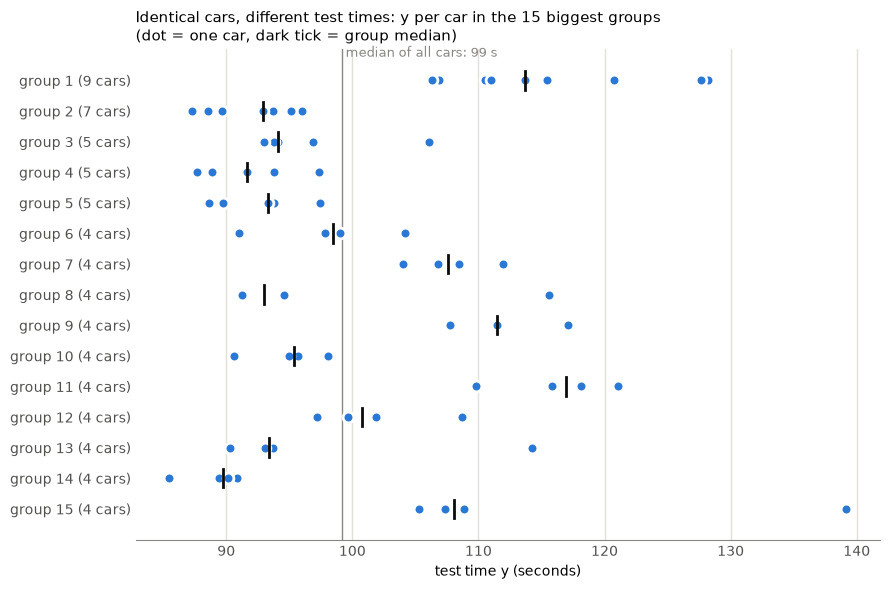

In [4]:
# Section 2, Step 4: H2.3 Spread of y inside each group
# Uses: train, config_id, in_group from Steps 1-3; chart colours from Step 1
y_by_group = train.loc[in_group, "y"].groupby(config_id[in_group])

# Spread per group: standard deviation (sd) and range (max - min) of the test time, in seconds
spread = pd.DataFrame({
    "cars": y_by_group.size(),
    "median_y": y_by_group.median(),
    "sd_y": y_by_group.std(ddof=1),
    "range_y": y_by_group.max() - y_by_group.min(),
})

summary = spread[["sd_y", "range_y"]].describe(percentiles=[0.25, 0.5, 0.75]).round(2)
summary.loc["sd of y over all cars"] = [round(train["y"].std(ddof=1), 2), np.nan]
print("Groups:", len(spread), "| groups with range > 10 s:", int((spread["range_y"] > 10).sum()))
display(summary)

# ONE plot: every car of the 15 biggest groups as a dot, the group median as a dark tick
top15 = spread.sort_values("cars", ascending=False, kind="stable").head(15)

fig, ax = plt.subplots(figsize=(9, 6))
for row, (gid, info) in enumerate(top15.iterrows()):
    times = train.loc[config_id == gid, "y"]
    ax.scatter(times, [row] * len(times), s=60, color=blue, edgecolor="white", linewidth=2, zorder=3)
    ax.plot([info["median_y"]] * 2, [row - 0.3, row + 0.3], color=ink, linewidth=2, zorder=4)

overall_median = train["y"].median()
ax.axvline(overall_median, color=muted, linewidth=1, zorder=1)
ax.text(overall_median, -0.9, f" median of all cars: {overall_median:.0f} s", color=muted, fontsize=9, va="center")

ax.set_yticks(range(len(top15)), [f"group {i + 1} ({n} cars)" for i, n in enumerate(top15["cars"])])
ax.invert_yaxis()
ax.set_xlabel("test time y (seconds)")
ax.set_title("Identical cars, different test times: y per car in the 15 biggest groups\n"
             "(dot = one car, dark tick = group median)", loc="left", fontsize=11)
ax.grid(axis="x", color=grid, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(muted)
ax.tick_params(colors=label_grey, length=0)
plt.tight_layout()
plt.show()

**Step 4 – reading the result**

| Spread inside a group (217 groups) | sd of `y` | range of `y` (max − min) |
|---|---|---|
| Median group | 3.50 s | 5.34 s |
| Middle half of groups (25 % – 75 %) | 1.93 – 6.91 s | 2.82 – 11.25 s |
| Largest | 41.41 s | 58.56 s |
| For comparison: sd of `y` over **all** 4,209 cars | 12.68 s | – |

- Groups whose fastest and slowest car differ by more than 10 s: **62 of 217**.
- In the plot, most groups sit in a band of about 5–15 s; a few single cars are far away (e.g. group 15: three cars at 105–109 s, one at 139 s).
- The 265 s car is **not** in any group (it has a unique configuration).

In simple words: identical cars get *similar* test times, but not the *same*. A typical group spreads about 3.5 s around its average, versus 12.7 s across all cars. So the options explain a large part of the time, but a part remains that the options cannot explain, for example two cars with exactly the same options, including the same X0 code, that still need different test times. Step 5 turns this into one number, the best possible R².

Note for Step 5: because the 265 s car has no twin, removing it changes only the variance over all cars, not the spread inside groups.

Own decision: (1) spread is measured with the sample sd (ddof = 1), the usual choice for small groups; (2) for the plot, ties at the "15 biggest" cut-off (15 groups have 4 cars, only 10 fit) are broken by the order in which the configuration first appears in the data, because any other order would be just as arbitrary and this one is reproducible.

### Step 5: H2.4 Best possible R²

If identical cars still get different times, no model can predict that part, because the model sees exactly the same options for them. We turn the spread inside groups (Step 4) into the best R² any model could reach: 1 − (pooled variance inside groups) / (total variance of `y`). We show the handover version (total variance over all cars, with and without the 265 s car) and a check version that uses the same 515 cars on both sides.

In [5]:
# Section 2, Step 5: H2.4 Best possible R²
# Uses: train, in_group, spread from Steps 1-4
# Pooled variance inside groups: each group's variance weighted by its degrees of freedom (cars - 1)
dof = spread["cars"] - 1
pooled_within_var = (dof * spread["sd_y"] ** 2).sum() / dof.sum()

y_all = train["y"]
y_no_outlier = y_all[y_all < 200]   # drops only the 265 s car
y_groups = y_all[in_group]           # the 515 cars that have at least one identical twin

rows = {
    "A) handover formula: all train cars": y_all,
    "A) handover formula: all cars without the 265 s car": y_no_outlier,
    "B) same cars on both sides: 515 cars in groups": y_groups,
}
result = pd.DataFrame({
    "cars in total variance": {k: len(v) for k, v in rows.items()},
    "pooled variance inside groups (s²)": pooled_within_var,
    "total variance (s²)": {k: v.var(ddof=1) for k, v in rows.items()},
})
result["best possible R²"] = 1 - result["pooled variance inside groups (s²)"] / result["total variance (s²)"]

print(f"Pooled variance inside groups: {pooled_within_var:.2f} s² "
      f"(from {int(dof.sum())} degrees of freedom = 515 cars - 217 groups)")
result.round(3)

Pooled variance inside groups: 64.87 s² (from 298 degrees of freedom = 515 cars - 217 groups)


,cars in total variance,pooled variance inside groups (s²),total variance (s²),best possible R²
A) handover formula: all train cars,4209,64.873,160.767,0.596
A) handover formula: all cars without the 265 s car,4208,64.873,154.359,0.580
B) same cars on both sides: 515 cars in groups,515,64.873,157.812,0.589


**Step 5 – reading the result**

Formula with the real numbers (version A, all train cars): best possible R² = 1 − 64.87 s² / 160.77 s² = 1 − 0.404 = **0.60**

- 64.87 s² = pooled variance inside the 217 groups (each group's variance weighted by cars − 1; 515 − 217 = 298 degrees of freedom). Its square root is 8.05 s, the typical distance of a car from its group average.
- 160.77 s² = variance of `y` over all 4,209 train cars (= 12.68 s squared, from Step 4).

| Version | Cars in total variance | Total variance | Best possible R² |
|---|---|---|---|
| A) handover formula, all train cars | 4,209 | 160.77 s² | **0.596** |
| A) without the 265 s car | 4,208 | 154.36 s² | 0.580 |
| B) same 515 cars on both sides (check) | 515 | 157.81 s² | 0.589 |

In simple words: about **60 %** of the differences in test time can be explained by the car's options at best. The other ~40 % differ even between identical cars, so no model can predict them from the options. All three versions give 0.58–0.60, so the choice of formula hardly matters. The 265 s car lowers the limit only slightly (0.596 → 0.580).

Why 8.05 s and not the 3.5 s median from Step 4: the pooled value weights the few groups with large spreads (up to 41 s sd), while the median ignores them. The limit is driven by those groups.

Own decision: (1) the main number for the slides is version A, all train cars (0.60), with versions A-without-outlier and B shown as a check, because all three agree within 0.02; (2) "without the 265 s car" is coded as `y < 200`, because 265.32 s is the only value above 200 (next highest: 169.91 s), so the cut removes exactly that one car.

### Step 6: H2.5 Reading the result

We compare the best possible R² from Step 5 with the Kaggle winners (≈ 0.55) and check how stable the limit is, because it rests on only 515 cars. This answers H2 and tells us what score our own models (M2/M3) can realistically aim for.

In [6]:
# Section 2, Step 6: H2.5 Reading the result
# Uses: result, spread, pooled_within_var from Steps 4-5
winner_r2 = 0.5555   # Kaggle winner: 1st place, private leaderboard 0.55550 (verified, D44)
best_r2 = result.loc["A) handover formula: all train cars", "best possible R²"]

print(f"Best possible R² (H2, version A): {best_r2:.3f}")
print(f"Kaggle winner (verified, D44):     {winner_r2:.4f}")
print(f"Winners reached {winner_r2 / best_r2:.0%} of the limit; gap {best_r2 - winner_r2:.3f}")

# Sensitivity: how much do the few very wide groups drive the limit?
calm = spread.sort_values("range_y").iloc[:-5]                 # leave out the 5 groups with the largest range
calm_var = ((calm["cars"] - 1) * calm["sd_y"] ** 2).sum() / (calm["cars"] - 1).sum()
print(f"Without the 5 widest groups: pooled variance {calm_var:.2f} s² "
      f"-> best possible R² {1 - calm_var / train['y'].var(ddof=1):.3f}")

Best possible R² (H2, version A): 0.596
Kaggle winner (verified, D44):     0.5555
Winners reached 93% of the limit; gap 0.041
Without the 5 widest groups: pooled variance 45.72 s² -> best possible R² 0.716


**Step 6 – reading the result**

| | R² |
|---|---|
| Best possible R² (H2, version A) | 0.596 |
| Kaggle winner (1st place, verified, D44) | 0.5555 |
| Winner's share of the limit | 93 % (gap 0.041) |
| Limit without the 5 widest of 217 groups (sensitivity) | 0.716 |

**Answer to H2 ("does the same car always need the same test time?"): no, only roughly.** Identical cars get similar times (typical spread 3.5 s), but a part of the time differs even between identical cars. From the options alone, at most about 60 % of the differences in test time can be explained.

**What this means for the project:**
- The Kaggle winners (1st place 0.5555, D44) were already close to this limit (about 93 % of it). A score around 0.55 is therefore **not weak**; it is near what the data allows. This is a strong message for the slides.
- Realistic target for our three models (M3): R² in the range of about 0.5–0.6 in cross validation. A clearly higher score would be a warning sign (e.g. leakage or a lucky split), not a success.

**Limitations (carried forward to M1.7 and the slides):**
1. **Small base:** the limit comes from 515 cars (12 %) in 217 groups, mostly pairs. The other 88 % have no twin, so we assume they behave like the cars in groups.
2. **Fragile number:** leaving out only the 5 widest groups raises the limit from 0.60 to 0.72. The limit is therefore a rough range (≈ 0.6–0.7), not an exact value; it depends on a few groups with very different times.
3. **Train vs. test:** the limit is measured on train data; Kaggle scored on the hidden test cars, whose spread may differ slightly.
4. **Unknown causes:** the unexplained part may come from things not in the data (e.g. which test bench, the day, the operator). For the options it looks like chance, but it might be explainable with more data.
5. **Winner value:** verified on the Kaggle Private Leaderboard: 1st place 0.55550 (D44); this step first used the approximate 0.55.

Own decision: (1) report the limit on slides as "about 0.6 (range 0.6–0.7)" rather than a single exact number, because of limitation 2; (2) the sensitivity check leaves out the 5 widest groups (≈ 2 % of the groups), a small, easy-to-explain cut; it is a check, not a cleaning step, so no groups are removed from the data.

## Section 3 (plan M1.4): Target y and the 265 s car

**Section 3 (Target y and the 265 s car) – Steps overview: understand the shape of the test time `y` and decide what to do with the one very long test (train data only, no data removed)**

| Step | Title | What it does | Source |
|---|---|---|---|
| 7 | Distribution of `y` | Summary (mean, median, percentiles 1/5/95/99 %) + one histogram of `y`; one smooth curve or several peaks? | Handover 10, plan v4 step 1.4 |
| 8 | The unusual test times | Lists the 10 longest tests (ID, y, X0) and counts cars above 1.5 × IQR and 3 × IQR over Q3; where does the 265 s car stand? | Handover 10, H5 (framing_h2_v2.md) |
| 9 | Keep or drop the 265 s car – proposal | Shows the effect on mean, sd and the H2 limit (Step 5); proposes keep/drop for M2/M3 (→ decided: D23) | Handover 10 |

### Step 7: Distribution of `y`

Before deciding anything about the 265 s car, we look at the shape of all test times: where most cars lie, how wide the spread is, and whether `y` is one smooth curve or has several peaks (several peaks would hint at different "types" of test).

,y (seconds)
mean,100.67
median,99.15
sd,12.68
1 %,74.87
5 %,85.78
25 %,90.82
75 %,109.01
95 %,120.81
99 %,137.43
max,265.32


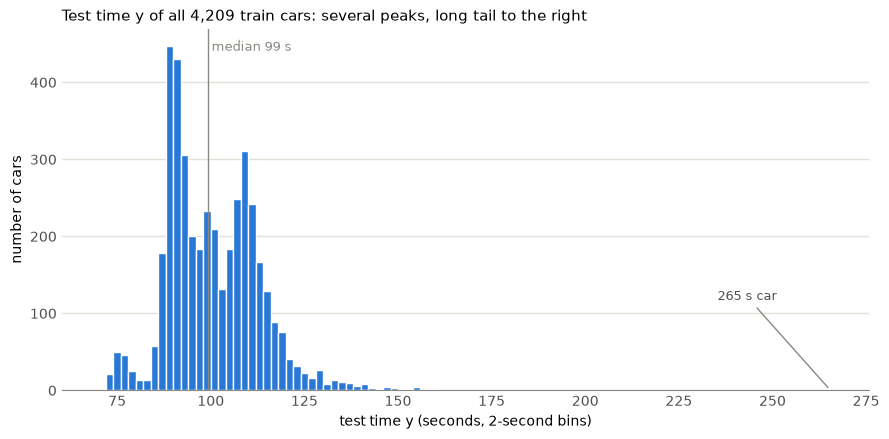

In [7]:
# Section 3, Step 7: Distribution of y
# Uses: train and chart colours from Step 1
y = train["y"]

summary_y = pd.Series({
    "mean": y.mean(),
    "median": y.median(),
    "sd": y.std(ddof=1),
    "1 %": y.quantile(0.01),
    "5 %": y.quantile(0.05),
    "25 %": y.quantile(0.25),
    "75 %": y.quantile(0.75),
    "95 %": y.quantile(0.95),
    "99 %": y.quantile(0.99),
    "max": y.max(),
}, name="y (seconds)").round(2)
display(summary_y.to_frame())

# ONE plot: histogram of y, 2-second bins
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(y, bins=np.arange(70, 268, 2), color=blue, edgecolor="white", linewidth=1)
ax.axvline(y.median(), color=muted, linewidth=1)
ax.text(y.median(), ax.get_ylim()[1] * 0.97, f" median {y.median():.0f} s", color=muted, fontsize=9, va="top")
ax.annotate("265 s car", xy=(y.max(), 1), xytext=(y.max() - 30, ax.get_ylim()[1] * 0.25),
            color=label_grey, fontsize=9, arrowprops=dict(arrowstyle="-", color=muted, linewidth=1))
ax.set_xlabel("test time y (seconds, 2-second bins)")
ax.set_ylabel("number of cars")
ax.set_title("Test time y of all 4,209 train cars: several peaks, long tail to the right", loc="left", fontsize=11)
ax.grid(axis="y", color=grid, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(muted)
ax.tick_params(colors=label_grey, length=0)
plt.tight_layout()
plt.show()

**Step 7 – reading the result**

| Measure | `y` (seconds) |
|---|---|
| Mean · median · sd | 100.67 · 99.15 · 12.68 |
| 1 % · 5 % | 74.87 · 85.78 |
| 25 % · 75 % (middle half) | 90.82 – 109.01 |
| 95 % · 99 % | 120.81 · 137.43 |
| Max | 265.32 |

- **Not one smooth curve: several peaks.** A small group around 72–78 s, the highest peak at 88–92 s (about 880 cars in these two 2-s bins), a smaller one around 98–102 s and a second large one around 106–112 s.
- **Long tail to the right:** 99 % of the cars are below 137 s; the tail thins out by about 160 s. The 265 s car stands alone, about 95 s beyond the next car (169.91 s, Step 5).
- Mean (100.7) is a bit above the median (99.2), as expected with a right tail.

In simple words: most tests take 85–120 s, but they cluster in a few "typical" lengths, as if each car belonged to one of a few groups with its own usual test time. This suggests a few options (probably text columns such as X0) decide which cluster a car falls into; M1.5 checks this. The 265 s car is far outside everything else; Steps 8–9 look at it.

Own decision: the histogram uses 2-second bins and the full range up to 265 s, because 2 s is fine enough to show the separate peaks, and the full range makes the gap to the 265 s car visible (its single bar is too small to see, so it is labelled).

### Step 8: The unusual test times

We look at the longest tests in detail and count how many cars lie above two common limits (Q3 + 1.5 × IQR and Q3 + 3 × IQR). This tells us whether the 265 s car is part of a natural long tail or a single case far outside it.

In [8]:
# Section 3, Step 8: The unusual test times
# Uses: train, y from Steps 1 and 7
# The 10 longest tests (only ID, y and X0 - never the full 378 columns)
longest = train.nlargest(10, "y")[["ID", "y", "X0"]].reset_index(drop=True)
longest.index = longest.index + 1
longest["gap to next (s)"] = (longest["y"] - longest["y"].shift(-1)).round(2)
display(longest)

# Clear limits above the upper quartile (Q3), using the interquartile range IQR = Q3 - Q1
q1, q3 = y.quantile(0.25), y.quantile(0.75)
iqr = q3 - q1
limits = pd.DataFrame({
    "limit (s)": [q3 + 1.5 * iqr, q3 + 3 * iqr],
}, index=["Q3 + 1.5 × IQR (usual outlier rule)", "Q3 + 3 × IQR (far outlier)"])
limits["cars above"] = [int((y > lim).sum()) for lim in limits["limit (s)"]]
limits["share of cars"] = (limits["cars above"] / len(y) * 100).round(2).astype(str) + " %"
print(f"Q1 = {q1:.2f} s, Q3 = {q3:.2f} s, IQR = {iqr:.2f} s")
display(limits.round(2))

# Where does the 265 s car stand?
max_y, second_y = y.nlargest(2)
print(f"265 s car: {max_y:.2f} s = {(max_y - y.median()) / y.std(ddof=1):.1f} sd above the median; "
      f"{max_y - second_y:.2f} s longer than the next car ({second_y:.2f} s); "
      f"{max_y / (q3 + 3 * iqr):.1f} × the far-outlier limit")

# Context: the other cars with the same X0 value as the 265 s car
x0_max = train.loc[y.idxmax(), "X0"]
same_x0 = y[(train["X0"] == x0_max) & (y.index != y.idxmax())]
print(f"Other cars with X0 = '{x0_max}': {len(same_x0)} cars, "
      f"median {same_x0.median():.2f} s, max {same_x0.max():.2f} s")

,ID,y,X0,gap to next (s)
1,1770,265.32,y,95.41
2,681,169.91,aa,2.46
3,2903,167.45,ai,1.93
4,6273,165.52,aj,4.65
5,2396,160.87,j,2.34
6,1784,158.53,aj,0.30
7,5471,158.23,x,2.61
8,7500,155.62,x,0.75
9,836,154.87,ak,0.44
10,2111,154.43,w,NaN


Q1 = 90.82 s, Q3 = 109.01 s, IQR = 18.19 s


,limit (s),cars above,share of cars
Q3 + 1.5 × IQR (usual outlier rule),136.30,50,1.19 %
Q3 + 3 × IQR (far outlier),163.58,4,0.1 %


265 s car: 265.32 s = 13.1 sd above the median; 95.41 s longer than the next car (169.91 s); 1.6 × the far-outlier limit
Other cars with X0 = 'y': 323 cars, median 91.44 s, max 134.81 s


**Step 8 – reading the result**

| Limit | Value | Cars above | Share |
|---|---|---|---|
| Q3 + 1.5 × IQR (usual outlier rule) | 136.30 s | 50 | 1.19 % |
| Q3 + 3 × IQR (far outlier) | 163.58 s | 4 | 0.10 % |

(Q1 = 90.82 s, Q3 = 109.01 s, IQR = 18.19 s.)

- **The 10 longest tests:** 265.32 s, then 169.91, 167.45, 165.52, 160.87 … 154.43 s. From place 2 to 10 the steps between neighbours are small (0.3–4.7 s), a smooth tail. Between place 1 and place 2 the gap is **95.41 s**.
- **The 265 s car** is 13.1 sd above the median and 1.6 × the far-outlier limit. Its X0 value is "y"; the other 323 cars with X0 = "y" have a median of 91.44 s and a maximum of 134.81 s, so even within its own kind it takes about twice as long as the slowest other car.
- The 50 cars above 136 s come with different X0 values (e.g. aa, ai, aj, j, x, ak, w among the top 10). They form the natural right tail seen in Step 7.

In simple words: long tests exist (about 1 in 80 cars takes more than 136 s), and they follow a smooth tail up to about 170 s. The 265 s car does not belong to this tail; it is a single case far outside, most likely a test that went wrong (e.g. a stop or repeat), not a normal long test. Step 9 shows what keeping or dropping it would change.

Own decision: (1) only the single 265 s car is treated as the "outlier" for Step 9; the other 49 cars above 136 s are kept as normal long tests, because they form a smooth tail with small gaps and different X0 values; (2) the "test went wrong" explanation is a guess, labelled as such, because the data has no column that records it.

### Step 9: Keep or drop the 265 s car – proposal

We compare the key numbers with and without the 265 s car (mean, median, sd, variance, H2 limit from Step 5) and measure how much of the total spread this single car causes. From that we propose whether the models in M2/M3 should learn from it. Nothing is removed here; this is a proposal only.

In [9]:
# Section 3, Step 9: Keep or drop the 265 s car - proposal
# Uses: y from Step 7, pooled_within_var from Step 5
# Proposal only: no data is removed here
outlier = y.idxmax()            # the 265 s car (only car above 200 s, Step 5)
y_without = y.drop(outlier)

compare = pd.DataFrame({
    "with 265 s car": [len(y), y.mean(), y.median(), y.std(ddof=1), y.var(ddof=1)],
    "without": [len(y_without), y_without.mean(), y_without.median(), y_without.std(ddof=1), y_without.var(ddof=1)],
}, index=["cars", "mean (s)", "median (s)", "sd (s)", "variance (s²)"])
compare.loc["H2 best possible R²"] = [1 - pooled_within_var / y.var(ddof=1),
                                      1 - pooled_within_var / y_without.var(ddof=1)]
compare["change"] = compare["without"] - compare["with 265 s car"]
display(compare.round(3))

# How much of the total spread comes from this one car?
squared_dev = (y - y.mean()) ** 2
print(f"Share of all squared deviations from this one car: {squared_dev[outlier] / squared_dev.sum():.1%} "
      f"(1 car = {1 / len(y):.2%} of the cars)")

,with 265 s car,without,change
cars,4209.000,4208.000,-1.000
mean (s),100.669,100.630,-0.039
median (s),99.150,99.150,0.000
sd (s),12.679,12.424,-0.255
variance (s²),160.767,154.359,-6.407
H2 best possible R²,0.596,0.580,-0.017


Share of all squared deviations from this one car: 4.0% (1 car = 0.02% of the cars)


**Step 9 – reading the result**

| | With the 265 s car | Without | Change |
|---|---|---|---|
| Cars | 4,209 | 4,208 | −1 |
| Mean | 100.67 s | 100.63 s | −0.04 s |
| Median | 99.15 s | 99.15 s | 0 |
| sd | 12.68 s | 12.42 s | −0.26 s |
| Variance | 160.77 s² | 154.36 s² | −6.41 s² (−4 %) |
| H2 best possible R² | 0.596 | 0.580 | −0.017 |

- **One car (0.02 % of the cars) causes 4.0 % of the total spread** (sum of squared deviations from the mean).
- Mean and median hardly move; the spread (sd, variance) and the H2 limit move noticeably for a single car.

In simple words: the 265 s car barely changes the "typical" test time, but it pulls hard on anything that measures squared errors. Our models (and R²) work with squared errors, so a model trained with this car would bend toward one test that was most likely faulty (Step 8). In cross validation, the fold that contains it would get a much worse score by chance.

Own decision: (1) **drop the 265 s car from the training data for M2/M3** (models and cross validation), because it is a single case far outside the smooth tail (Step 8), probably a faulty test, and alone it makes up 4 % of the total spread; the Kaggle test data is not affected (it has no `y`); (2) the drop is done at the start of M2 with one visible code line (`y < 200`, as in Step 5), not earlier, so Sections 1–3 keep describing the full data; (3) when our model scores are compared with the H2 limit, use the limit **without** the car (0.58) so both sides use the same cars; on the slides "about 0.6 (range 0.6–0.7)" (R8) still holds.

## Section 4 (plan M1.5): The text columns

**Section 4 (The text columns) – Steps overview: understand the 8 text columns X0–X8 and how X0 relates to the test time (train data; test.csv only in Step 12; nothing is encoded or removed)**

| Step | Title | What it does | Source |
|---|---|---|---|
| 10 | Levels per text column | For X0–X8: number of distinct values, number of rare values (< 1 % of cars = fewer than 43 cars), top 3 values with counts; one table | Handover 11, plan v5 step 1.5 |
| 11 | `y` per X0 value | Median `y` and count per X0 value; do X0 values line up with the peaks of Step 7 (≈ 75 / 90 / 100 / 108 s)? Strongest other text column by share of `y` variance explained by its group means; one box plot | Handover 11, H1/H4 (framing_h2_v2.md) |
| 12 | Values only in test.csv | Per text column: values in test.csv but not in train and how many test cars they affect; encoding proposal for M2 (→ decided: D25) | Handover 11 |

### Step 10: Levels per text column

The 8 text columns (X0–X6, X8; there is no X7) describe car options with letter codes. For each column we count how many different values it has, how many of them are rare (fewer than 43 cars, i.e. < 1 % of the cars), and which values are most common. This shows which columns carry a lot of detail and which are almost the same for every car.

In [10]:
# Section 4, Step 10: Levels per text column
# Uses: train, text_cols from Step 1
rare_limit = 0.01 * len(train)   # 1 % of 4,209 cars = 42.09 -> rare = fewer than 43 cars

rows = []
for col in text_cols:            # X0, X1, X2, X3, X4, X5, X6, X8 (there is no X7)
    counts = train[col].value_counts()
    rare = counts[counts < rare_limit]
    rows.append({
        "column": col,
        "distinct values": len(counts),
        "rare values (< 43 cars)": len(rare),
        "cars in rare values": int(rare.sum()),
        "top 3 values (cars)": ", ".join(f"{v} ({n})" for v, n in counts.head(3).items()),
    })
levels = pd.DataFrame(rows).set_index("column")
levels

,distinct values,rare values (< 43 cars),cars in rare values,top 3 values (cars)
column,,,,
X0,47,29,453,"z (360), ak (349), y (324)"
X1,27,15,290,"aa (833), s (598), b (592)"
X2,44,31,291,"as (1659), ae (496), ai (415)"
X3,7,0,0,"c (1942), f (1076), a (440)"
X4,4,3,4,"d (4205), a (2), b (1)"
X5,29,7,33,"v (231), w (231), q (220)"
X6,12,4,98,"g (1042), j (1039), d (625)"
X8,25,0,0,"j (277), s (255), f (243)"


**Step 10 – reading the result**

| Column | Distinct values | Rare values (< 43 cars) | Cars in rare values | Top 3 values (cars) |
|---|---|---|---|---|
| X0 | 47 | 29 | 453 | z (360), ak (349), y (324) |
| X1 | 27 | 15 | 290 | aa (833), s (598), b (592) |
| X2 | 44 | 31 | 291 | as (1,659), ae (496), ai (415) |
| X3 | 7 | 0 | 0 | c (1,942), f (1,076), a (440) |
| X4 | 4 | 3 | 4 | d (4,205), a (2), b (1) |
| X5 | 29 | 7 | 33 | v (231), w (231), q (220) |
| X6 | 12 | 4 | 98 | g (1,042), j (1,039), d (625) |
| X8 | 25 | 0 | 0 | j (277), s (255), f (243) |

- **Many values, many of them rare:** X0 (47 values, 29 rare), X2 (44, 31 rare) and X1 (27, 15 rare). For a model, a rare value is learned from only a few cars.
- **X4 is almost constant:** 4,205 of 4,209 cars (99.9 %) have "d"; the other 3 values cover only 4 cars. X4 can hardly explain any difference in test time.
- **Evenly spread columns:** X5 and X8 have many values, but none dominates (largest only 231 / 277 cars).
- **X3 is simple:** 7 values, none rare.

In simple words: X0, X1 and X2 are the "detailed" options with many variants, X4 is practically the same on every car, and the rest lie in between. Step 11 checks whether the detailed X0 explains the peaks of the test time.

Own decision: R16) "rare" is computed as fewer than 1 % of the train cars (< 42.09 → at most 42 cars), as in handover 11, so the limit follows the data size instead of a fixed number; R17) X4 is flagged as **almost constant** and proposed as a candidate to leave out in M2.0 (data preparation), because 99.9 % of the cars share one value. Nothing is removed in this section.

### Step 11: `y` per X0 value

Step 7 showed that test times cluster in a few peaks. Here we check whether X0, the text column with the most values, explains these peaks: for each X0 value we take the median test time and see which peak it falls into. We also measure how much of the differences in `y` each text column explains on its own, and show one box plot of `y` per X0 value.

,X0_values,cars,X0 values (median y)
median y of the X0 value,,,
≈ 75 s,2,181,"bc (77), az (77)"
≈ 90 s,21,2089,"ac (90), am (90), l (90), b (90), aq (90), u (91), ad (91), e (91), al (91), s (91), n (91), y (91), t (92), ai (92), k (92), f (92), z (92), o (92), ba (93), m (93), q (93)"
≈ 100 s,7,668,"d (100), ay (101), h (102), aj (102), v (103), ao (104), aw (104)"
≈ 108 s,16,1269,"c (109), ax (109), x (110), j (110), w (110), i (110), ak (110), g (111), at (111), ab (112), af (113), r (113), as (114), a (114), ap (115), au (116)"
> 120 s,1,2,aa (152)


Share of y variance explained by X0 alone: 57.5%
Strongest other text column: X2 (22.6%)


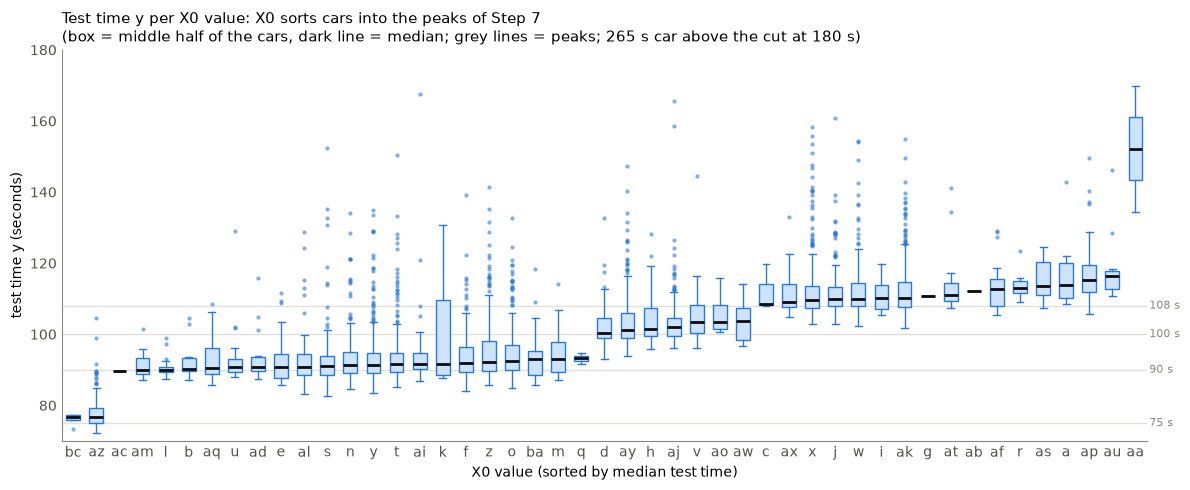

In [11]:
# Section 4, Step 11: y per X0 value
# Uses: train, y, text_cols from Steps 1 and 7; chart colours from Step 1
x0_stats = train.groupby("X0")["y"].agg(cars="size", median_y="median").sort_values("median_y")

# Which peak of Step 7 is each X0 value's median closest to? (peaks at about 75 / 90 / 100 / 108 s)
peak_bands = pd.cut(x0_stats["median_y"], bins=[0, 82, 95, 104, 120, 300],
                    labels=["≈ 75 s", "≈ 90 s", "≈ 100 s", "≈ 108 s", "> 120 s"])
by_peak = x0_stats.groupby(peak_bands, observed=False).agg(
    X0_values=("cars", "size"), cars=("cars", "sum"))
by_peak["X0 values (median y)"] = [
    ", ".join(f"{v} ({m:.0f})" for v, m in x0_stats.loc[peak_bands == band, "median_y"].items())
    for band in by_peak.index]
with pd.option_context("display.max_colwidth", None):   # show the full list of X0 values
    display(by_peak.rename_axis("median y of the X0 value"))


# Share of y variance explained by the group means (eta squared); cols = one column or a list of columns
# (one function for Steps 11, 15 and 16)
def explained_share(cols):
    group_mean = train.groupby(cols)["y"].transform("mean")
    return ((group_mean - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()


shares = pd.Series({col: explained_share(col) for col in text_cols}).sort_values(ascending=False)
strongest_other = shares.drop("X0").idxmax()
print(f"Share of y variance explained by X0 alone: {shares['X0']:.1%}")
print(f"Strongest other text column: {strongest_other} ({shares[strongest_other]:.1%})")

# ONE plot: y per X0 value, sorted by median (box plot); y-axis cut at 180 s so the boxes stay readable
order = x0_stats.index.tolist()
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([y[train["X0"] == v] for v in order], tick_labels=order, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=blue, linewidth=1),
           medianprops=dict(color=ink, linewidth=2), whiskerprops=dict(color=blue), capprops=dict(color=blue),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=blue, markeredgecolor="none", alpha=0.6))
for peak in [75, 90, 100, 108]:
    ax.axhline(peak, color=grid, linewidth=1, zorder=0)
    ax.text(len(order) + 0.6, peak, f"{peak} s", color=muted, fontsize=8, va="center")
ax.set_ylim(70, 180)
ax.set_xlabel("X0 value (sorted by median test time)")
ax.set_ylabel("test time y (seconds)")
ax.set_title("Test time y per X0 value: X0 sorts cars into the peaks of Step 7\n"
             "(box = middle half of the cars, dark line = median; grey lines = peaks; "
             "265 s car above the cut at 180 s)",
             loc="left", fontsize=11)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(muted)
ax.spines["left"].set_color(muted)
ax.tick_params(colors=label_grey, length=0)
plt.tight_layout()
plt.show()

**Step 11 – reading the result**

| Median `y` of the X0 value | X0 values | Cars | X0 values (median `y` in s) |
|---|---|---|---|
| ≈ 75 s | 2 | 181 | bc (77), az (77) |
| ≈ 90 s | 21 | 2,089 | ac, am, l, b, aq, u, ad, e, al, s, n, y, t, ai, k, f, z, o, ba, m, q (90–93) |
| ≈ 100 s | 7 | 668 | d, ay, h, aj, v, ao, aw (100–104) |
| ≈ 108 s | 16 | 1,269 | c, ax, x, j, w, i, ak, g, at, ab, af, r, as, a, ap, au (109–116) |
| > 120 s | 1 | 2 | aa (152) |

- **Yes, X0 lines up with the peaks.** Every X0 value has its median in one of the bands, and the bands match the peaks of Step 7: about half of the cars (2,089) have an X0 value with a median of 90–93 s, about 1,270 one with 109–116 s.
- **X0 alone explains 57.5 % of the differences in `y`** (share of variance explained by its group means). That is close to the H2 limit (≈ 0.60, Step 5).
- **Strongest other text column: X2, 22.6 %.** All others explain less than 5 % each (X3 4.2 %, X1 4.2 %, X8 2.8 %, X5 1.4 %, X6 1.1 %, X4 0.2 %).
- In the plot the boxes form clear "steps"; inside each step the spread is mostly 5–10 s, with long-test dots above the boxes.

In simple words: X0 is the main option code of a car. It decides whether a car is in the "short", "normal", "longer" or "long" test group, and the other options only fine-tune the time inside that group.

**Caution:** the 57.5 % is measured on the same cars it was computed from. X0 has many rare values (Step 10), and for those the group mean fits a few cars very closely. In cross validation (M2) the score of X0 alone will be lower. This links to H1 ("single options explain a clear part of the test time"): confirmed for X0.

Own decision: R18) the X0 values are assigned to peaks by fixed bands around the Step 7 peaks (< 82 / 82–95 / 95–104 / 104–120 / > 120 s), because all medians fall clearly inside one band and the bands follow the histogram; R19) the plot's y-axis is cut at 180 s so the 47 boxes stay readable; the 265 s car (X0 = "y") is above the cut, which is said in the title; R20) X0 is proposed as a key feature for the M2 baseline (rule baseline "average per X0 value", plan step 2.2), because alone it explains 57.5 % in-sample.

### Step 12: Values only in test.csv

A model can only learn from values it has seen in the training data. Here we check, for each text column, which values appear only in `test.csv` (the Kaggle cars without `y`) and how many test cars they affect. From that we propose how the encoding in M2 should treat them. Nothing is encoded here; this is a proposal only.

In [12]:
# Section 4, Step 12: Values only in test.csv
# Uses: train, text_cols from Step 1; reads data/test.csv
test = pd.read_csv("data/test.csv")   # cars without y (Kaggle test set) - used only for this check
print("Test shape:", test.shape)

rows = []
for col in text_cols:
    only_test = sorted(set(test[col]) - set(train[col]))
    only_train = set(train[col]) - set(test[col])
    rows.append({
        "column": col,
        "values only in test": len(only_test),
        "test cars affected": int(test[col].isin(only_test).sum()),
        "which values (test cars)": ", ".join(f"{v} ({(test[col] == v).sum()})" for v in only_test) or "-",
        "values only in train": len(only_train),
    })
unseen = pd.DataFrame(rows).set_index("column")
with pd.option_context("display.max_colwidth", None):
    display(unseen)

affected_any = test[text_cols].apply(lambda s: ~s.isin(set(train[s.name]))).any(axis=1)
print(f"Test cars with at least one unseen text value: {int(affected_any.sum())} of {len(test)} "
      f"({affected_any.mean():.2%})")

Test shape: (4209, 377)


,values only in test,test cars affected,which values (test cars),values only in train
column,,,,
X0,6,6,"ae (1), ag (1), an (1), av (1), bb (1), p (1)",4
X1,0,0,-,0
X2,6,14,"ab (4), ad (4), aj (1), ax (1), u (1), w (3)",5
X3,0,0,-,0
X4,0,0,-,0
X5,4,4,"a (1), b (1), t (1), z (1)",1
X6,0,0,-,0
X8,0,0,-,0


Test cars with at least one unseen text value: 24 of 4209 (0.57%)


**Step 12 – reading the result**

`test.csv`: 4,209 cars × 377 columns (no `y`).

| Column | Values only in test | Test cars affected | Which values (test cars) | Values only in train |
|---|---|---|---|---|
| X0 | 6 | 6 | ae, ag, an, av, bb, p (1 each) | 4 |
| X2 | 6 | 14 | ab (4), ad (4), w (3), aj, ax, u (1 each) | 5 |
| X5 | 4 | 4 | a, b, t, z (1 each) | 1 |
| X1, X3, X4, X6, X8 | 0 | 0 | – | 0 |

- **Check against the download report:** X0 6, X2 6, X5 4 unseen values, as expected.
- **24 of 4,209 test cars (0.57 %)** have at least one unseen text value (6 + 14 + 4, no car is affected twice).
- Each unseen value is very rare (1–4 test cars). Some train values never appear in test (X0: 4, X2: 5, X5: 1); this does no harm.

In simple words: almost all test cars only use option values the model has already seen. For about 1 car in 175 the model meets one new letter code (for example an X0 code that never appears in train.csv). It must still give a sensible time for them, but they hardly change the overall score.

Own decision: R21) in M2/M3 the text columns are one-hot encoded with "ignore unknown values" (an unseen value becomes all zeros, so the model uses the car's other options), because it needs no extra rule, works for all three algorithms and affects only 0.57 % of the test cars; R22) for the rule baseline "average per X0 value" (plan step 2.2), an unseen X0 value gets the overall train average, as the simplest fair fallback; R23) rare values (Step 10) are **not** merged into an "other" group for now; whether merging helps is checked in M2 with cross validation, because merging changes what the model can learn and should be judged by the CV score.

## Section 5 (plan M1.6): The 0/1 option columns

**Section 5 (The 0/1 option columns) – Steps overview: find the 368 0/1 columns that carry no information (constant or duplicate) and see which ones are linked to the test time `y` (train data, all 4,209 cars; the 265 s car stays until M2, D23; nothing is removed or encoded)**

| Step | Title | What it does | Source |
|---|---|---|---|
| 13 | Constant columns | Counts the 0/1 columns where every car has the same value (only 0 or only 1) and lists their names (≤ 15 shown, rest as a count); also counts columns where fewer than 1 % of the cars (≤ 42) differ from the rest | Handover 12, plan v6 step 1.6 |
| 14 | Duplicate columns | Counts groups of 0/1 columns that are identical for all cars (same 0/1 pattern): number of groups and how many columns could be left out; shows the 10 biggest groups | Handover 12 |
| 15 | Link to `y` (H3) | For each remaining 0/1 column: share of `y` differences explained (group-mean R² as in Step 11: cars with 1 vs cars with 0); top 10 table + how many columns explain > 1 %; one bar chart of the top 15; keep/drop proposal for M2.0 (→ decided: D27) | Handover 12, H3 (framing_h2_v2.md) |

### Step 13: Constant columns

A 0/1 column where every car has the same value cannot tell two cars apart, so it cannot help any model predict `y`. We count these constant columns and also the "almost constant" ones, where fewer than 1 % of the cars (at most 42) differ from the rest; for those, a model would learn from very few cars.

In [13]:
# Section 5, Step 13: Constant columns
# Uses: train, binary_cols from Step 1; rare_limit from Step 10
ones = train[binary_cols].sum()                  # cars with 1 per column
zeros = len(train) - ones                        # cars with 0 per column
minority = pd.concat([ones, zeros], axis=1).min(axis=1)   # cars that differ from the majority value

constant_cols = minority[minority == 0].index.tolist()    # every car has the same value
near_constant = minority[(minority > 0) & (minority < rare_limit)]   # 1 to 42 cars differ (< 1 %)
# the rare value is 1 (option seldom fitted)
rare_is_one = (ones[near_constant.index] < zeros[near_constant.index]).sum()

print("0/1 columns:", len(binary_cols))
print("Constant columns (only 0 or only 1):", len(constant_cols),
      "| only 0:", int((ones[constant_cols] == 0).sum()), "| only 1:", int((zeros[constant_cols] == 0).sum()))
print("Names (max 15 shown):", constant_cols[:15], "| not shown:", max(0, len(constant_cols) - 15))
print(f"Almost constant (1-42 cars differ, < 1 %): {len(near_constant)} columns",
      f"| rare value is 1: {rare_is_one} | rare value is 0: {len(near_constant) - rare_is_one}")
print("Cars that differ in the almost-constant columns: median", int(near_constant.median()),
      "| min", int(near_constant.min()), "| max", int(near_constant.max()),
      "| exactly 1 car:", int((near_constant == 1).sum()))
print("Constant + almost constant:", len(constant_cols) + len(near_constant), "of", len(binary_cols),
      f"({(len(constant_cols) + len(near_constant)) / len(binary_cols):.1%})")

0/1 columns: 368
Constant columns (only 0 or only 1): 12 | only 0: 12 | only 1: 0
Names (max 15 shown): ['X11', 'X93', 'X107', 'X233', 'X235', 'X268', 'X289', 'X290', 'X293', 'X297', 'X330', 'X347'] | not shown: 0
Almost constant (1-42 cars differ, < 1 %): 135 columns | rare value is 1: 133 | rare value is 0: 2
Cars that differ in the almost-constant columns: median 11 | min 1 | max 42 | exactly 1 car: 18
Constant + almost constant: 147 of 368 (39.9%)


**Step 13 – reading the result**

| Check | Result |
|---|---|
| 0/1 columns | 368 |
| Constant columns | **12**, all only 0 (no car has the option): X11, X93, X107, X233, X235, X268, X289, X290, X293, X297, X330, X347 |
| Almost constant (1–42 cars differ, < 1 %) | **135** columns; in 133 the rare value is 1 (an option fitted to very few cars), in 2 it is 0 |
| Cars that differ in these 135 columns | median 11, min 1, max 42; 18 columns differ for exactly 1 car |
| Constant + almost constant | 147 of 368 (39.9 %) |

- **12 columns carry no information at all:** every car has 0. They cannot tell two cars apart, so no model can use them.
- **135 more columns are almost constant:** nearly all of them are options that only a few cars have (median 11 cars). A model learns such an option from a handful of cars, so its effect on `y` is very uncertain.
- **Together, about 4 in 10 of the 0/1 columns** are constant or almost constant. The real information sits in the remaining 221 columns, plus possible copies of each other (Step 14).

In simple words: besides X0 and the other text columns, each car has 368 extra 0/1 options. 12 of them are fitted on no car at all, and 135 differ on fewer than 43 of the 4,209 cars. From so few cars you cannot reliably tell how much such an option changes the test time.

Own decision: R24) "almost constant" uses the same limit as "rare" in Step 10 (R16): the value that fewer cars have appears in fewer than 1 % of the train cars (1–42 cars), so the two sections use one rule; R25) the 12 constant columns are proposed to be left out in M2.0 (data preparation), because they have the same value for every train car and so cannot help any model; the 135 almost-constant columns are **not** proposed for removal yet, because a rare option can still change the test time a lot – they are judged in Step 15 (link to `y`) and in M2 with cross validation. Nothing is removed in this step.

### Step 14: Duplicate columns

Two 0/1 columns that have exactly the same value for every car carry the same information twice: a model gains nothing from the second copy. We group the columns by their 0/1 pattern over all 4,209 cars, count the groups and how many columns could be left out (one kept per group), and show the 10 biggest groups.

In [14]:
# Section 5, Step 14: Duplicate columns
# Uses: train, binary_cols from Step 1; constant_cols from Step 13
# The 12 constant columns are all identical to each other (only 0) - already covered in Step 13, so left out here
check_cols = [c for c in binary_cols if c not in constant_cols]          # 356 columns


def x_number(col):   # "X10" -> 10: sorts 0/1 columns in X-number order (also used in Steps 15 and 17)
    return int(col[1:])


# the 0/1 pattern over all 4,209 cars, one text per column
pattern = train[check_cols].astype(str).agg("".join, axis=0)
groups = [list(cols) for cols in pattern.groupby(pattern).groups.values() if len(cols) > 1]
groups = [sorted(g, key=x_number) for g in groups]                      # X-number order inside a group
groups.sort(key=lambda g: (-len(g), x_number(g[0])))                    # biggest groups first

can_leave_out = sum(len(g) - 1 for g in groups)                         # keep one column per group
print("Columns checked (0/1 without the 12 constant ones):", len(check_cols))
print("Groups of identical columns:", len(groups), "| columns in these groups:", sum(len(g) for g in groups))
print("Columns that could be left out (keep one per group):", can_leave_out)
print("Distinct 0/1 columns left:", len(check_cols) - can_leave_out)

dup_table = pd.DataFrame({
    "columns in group": [len(g) for g in groups[:10]],
    "cars with 1": [int(train[g[0]].sum()) for g in groups[:10]],
    "columns": [", ".join(g) for g in groups[:10]],
}, index=pd.RangeIndex(1, min(10, len(groups)) + 1, name="group"))
dup_table

Columns checked (0/1 without the 12 constant ones): 356
Groups of identical columns: 28 | columns in these groups: 73
Columns that could be left out (keep one per group): 45
Distinct 0/1 columns left: 311


,columns in group,cars with 1,columns
group,,,
1,5,94,"X48, X113, X134, X147, X222"
2,4,29,"X53, X102, X214, X239"
3,4,6,"X60, X248, X253, X385"
4,4,30,"X88, X122, X243, X320"
5,3,181,"X29, X232, X279"
6,3,978,"X31, X35, X37"
7,3,25,"X62, X172, X216"
8,3,436,"X71, X84, X244"
9,3,31,"X90, X94, X242"


**Step 14 – reading the result**

| Check | Result |
|---|---|
| Columns checked (0/1 without the 12 constant ones from Step 13) | 356 |
| Groups of identical columns (≥ 2 columns, same 0/1 value for every car) | **28** (73 columns) |
| Group sizes | 1 group of 5, 3 groups of 4, 8 groups of 3, 16 pairs |
| Columns that could be left out (one kept per group) | **45** |
| Distinct 0/1 columns left | 311 |
| Groups whose option is almost constant (Step 13) | 16 of 28 (26 of the 45 columns) |

- **45 columns are exact copies** of another column: for all 4,209 cars they show the same 0/1 value. Keeping one column per group loses no information.
- **Biggest group:** X48, X113, X134, X147, X222 – five columns, always 1 for the same 94 cars. Probably one real option recorded in five places (for example, a package that always comes together).
- **Some copies are common options:** X31, X35, X37 are 1 for 978 cars; X71, X84, X244 for 436 cars. So duplicates are not only a rare-option effect, although 16 of the 28 groups are almost constant (Step 13).
- **Together with Step 13:** 12 constant + 45 duplicate columns = 57 of 368 columns add no new information; 311 distinct 0/1 columns remain.

In simple words: some 0/1 options have different column names but are always fitted on exactly the same cars – for example X29, X232 and X279. The model only needs one of these columns to know which cars have the option.

Own decision: R26) the 12 constant columns are left out of the duplicate check, because they form one trivial group (all 0) that Step 13 already covers; counting them again would mix the two findings (with them: 29 groups, 56 columns); R27) only **exact** copies count as duplicates (same value for every train car); columns that are almost the same, or exact opposites (one is 1 where the other is 0), are not counted, because handover 12 asks for identical patterns and "almost the same" would need an extra limit; R28) proposal for M2.0: keep the column with the lowest X number in each group and leave out the other 45, because the copies add no information for any of the models; the kept column stands for the whole group in Step 15. Nothing is removed in this step.

### Step 15: Link to `y` (H3)

Hypothesis H3 asks whether single 0/1 options are linked to the test time. For each remaining 0/1 column (not constant, one column per duplicate group) we measure the share of the differences in `y` explained by comparing the average time of cars with 1 and cars with 0 – the same group-mean R² as in Step 11. We also count exact-opposite column pairs (open point from Step 14, added on Mohammad's request) and show the 15 strongest columns in one bar chart.

Remaining 0/1 columns: 311
Exact-opposite pairs among them: 8 | [('X128', 'X130'), ('X142', 'X158'), ('X156', 'X157'), ('X186', 'X194'), ('X204', 'X205')]
Columns that explain > 1 % of y differences: 99 | > 5 %: 27 | > 10 %: 13
Almost-constant columns (Step 13) among the remaining: 109 | of them > 1 %: 4
Median share of all remaining columns: 0.26%


,share of y explained,cars with 1,mean y with 1 (s),mean y with 0 (s),copies (Step 14)
column,,,,,
X314,36.7%,1817,109.5,94.0,–
X261,34.7%,1766,109.4,94.3,–
X127,26.1%,2084,94.1,107.1,–
X263,14.4%,4028,101.7,78.0,–
X29,14.4%,181,78.0,101.7,"X232, X279"
X136,13.6%,4026,101.7,78.8,–
X54,13.6%,183,78.8,101.7,X76
X328,13.4%,169,78.0,101.6,–
X276,12.9%,162,77.9,101.6,–


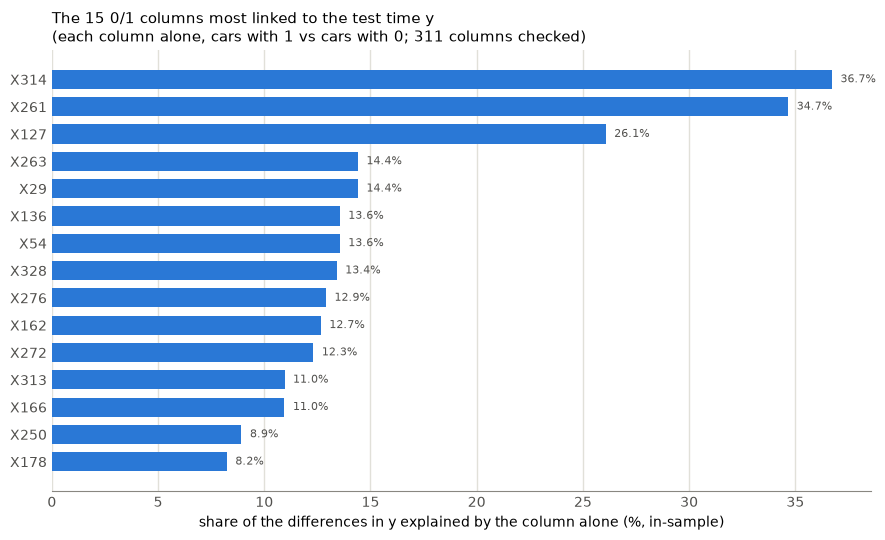

In [15]:
# Section 5, Step 15: Link to y (H3)
# Uses: train, y, check_cols, groups, x_number, near_constant, explained_share from Steps 1, 7, 11, 13, 14;
#       chart colours from Step 1
# Remaining columns: not constant (Step 13), one column per duplicate group (lowest X number, R28)
left_out = {c for g in groups for c in g[1:]}
remaining = [c for c in check_cols if c not in left_out]           # 311 columns

# Exact opposites (R27): pairs where one column is 1 exactly where the other is 0
pattern_left = pattern[remaining]
flipped = train[remaining].rsub(1).astype(str).agg("".join, axis=0)   # 1 - column, as a 0/1 text
lookup = pd.Series(pattern_left.index, index=pattern_left.values)
opposite_pairs = sorted({tuple(sorted([c, lookup[f]], key=x_number))
                         for c, f in flipped.items() if f in lookup.index})

# Share of y differences explained by each column (group-mean R² as in Step 11: cars with 1 vs cars with 0)
shares_bin = pd.Series({c: explained_share(c) for c in remaining}).sort_values(ascending=False)

print("Remaining 0/1 columns:", len(remaining))
print("Exact-opposite pairs among them:", len(opposite_pairs), "|", opposite_pairs[:5])
print("Columns that explain > 1 % of y differences:", int((shares_bin > 0.01).sum()),
      "| > 5 %:", int((shares_bin > 0.05).sum()), "| > 10 %:", int((shares_bin > 0.10).sum()))
print("Almost-constant columns (Step 13) among the remaining:", len(near_constant.index.intersection(remaining)),
      "| of them > 1 %:", int((shares_bin[shares_bin.index.isin(near_constant.index)] > 0.01).sum()))
print(f"Median share of all remaining columns: {shares_bin.median():.2%}")

top10 = pd.DataFrame({
    "share of y explained": shares_bin.head(10).map("{:.1%}".format),
    "cars with 1": train[shares_bin.head(10).index].sum().astype(int),
    "mean y with 1 (s)": [y[train[c] == 1].mean().round(1) for c in shares_bin.head(10).index],
    "mean y with 0 (s)": [y[train[c] == 0].mean().round(1) for c in shares_bin.head(10).index],
    "copies (Step 14)": [", ".join(next((g[1:] for g in groups if g[0] == c), [])) or "–"
                         for c in shares_bin.head(10).index],
}).rename_axis("column")
display(top10)

# ONE plot: top 15 columns by share of y explained (horizontal bars, biggest on top)
top15 = shares_bin.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(top15.index, top15.values * 100, color=blue, height=0.7)
for bar, v in zip(bars, top15.values):
    ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2, f"{v:.1%}",
            va="center", fontsize=8, color=label_grey)
ax.set_xlabel("share of the differences in y explained by the column alone (%, in-sample)")
ax.set_title("The 15 0/1 columns most linked to the test time y\n"
             f"(each column alone, cars with 1 vs cars with 0; {len(remaining)} columns checked)",
             loc="left", fontsize=11)
ax.grid(axis="x", color=grid, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(muted)
ax.tick_params(colors=label_grey, length=0)
plt.tight_layout()
plt.show()

**Step 15 – reading the result**

| Check | Result |
|---|---|
| Remaining 0/1 columns (not constant, one per duplicate group) | 311 |
| Exact-opposite pairs (one column is 1 exactly where the other is 0) | **8**: X29/X263, X52/X120, X54/X136, X128/X130, X142/X158, X156/X157, X186/X194, X204/X205 |
| Columns that explain > 1 % / > 5 % / > 10 % of the `y` differences | **99** / 27 / 13 |
| Median share of all 311 columns | 0.26 % |
| Almost-constant columns (Step 13) among the 311 | 109, of which only 4 explain > 1 % |

| Column | Share of `y` explained | Cars with 1 | Mean `y` with 1 / with 0 (s) |
|---|---|---|---|
| X314 | 36.7 % | 1,817 | 109.5 / 94.0 |
| X261 | 34.7 % | 1,766 | 109.4 / 94.3 |
| X127 | 26.1 % | 2,084 | 94.1 / 107.1 |
| X263 | 14.4 % | 4,028 | 101.7 / 78.0 |
| X29 (copies X232, X279) | 14.4 % | 181 | 78.0 / 101.7 |
| X136 | 13.6 % | 4,026 | 101.7 / 78.8 |
| X54 (copy X76) | 13.6 % | 183 | 78.8 / 101.7 |
| X328 | 13.4 % | 169 | 78.0 / 101.6 |
| X276 | 12.9 % | 162 | 77.9 / 101.6 |
| X162 | 12.7 % | 172 | 78.8 / 101.6 |

- **H3 is confirmed: single 0/1 options are clearly linked to the test time.** 99 of 311 columns explain more than 1 % each. X314 alone explains 36.7 %: cars with this option take on average 15.5 s longer (109.5 s vs 94.0 s).
- **Most columns do almost nothing on their own:** half of them explain less than 0.26 %. The almost-constant options of Step 13 are mostly weak (only 4 of 109 above 1 %).
- **Opposite pairs show up in the top 10:** X29/X263 and X54/X136 are the same information flipped (14.4 % and 13.6 % each), so the top 10 contains fewer than 10 different pieces of information.
- **The ≈ 78 s columns (X29, X54, X328, X276, X162)** mark the about 170–180 cars of the short-test peak (≈ 75 s in Step 7, X0 = bc / az in Step 11).
- **Side check by Claude, outside this code cell:** X29 is 1 for exactly the 181 cars with X0 = bc or az, and X314, X29, X263, X54, X136 have only one value inside each X0 group. Adding any top-10 column to X0 raises the in-sample share by at most 0.04 percentage points (57.48 % → at most 57.52 %). So the strongest 0/1 columns mostly **repeat the information of X0**; the in-sample shares are not additive.
- The shares are in-sample (like Step 11): they will be lower in cross validation (M2).

In simple words: some 0/1 options change the test time a lot – but the strongest ones almost always come together with certain X0 codes, so they add little that the X0 code has not already said.

Own decision: R29) the link to `y` is measured on the 311 remaining columns (constant columns left out, one column per duplicate group as in R28), with the same group-mean R² as in Step 11, so the numbers of Sections 4 and 5 are comparable; both columns of an opposite pair are still shown, so the top 10 can be checked against the pairs; R30) proposal for M2.0: leave out the 12 constant columns (R25), the 45 duplicate copies (R28) and one column of each of the 8 opposite pairs (the one with the higher X number), so **303 of 368 0/1 columns stay**; opposite pairs are dropped because together with the intercept they make a linear regression unstable (one column is exactly 1 − the other) and add no information; R31) **no column is dropped because of a low share of `y` explained**, because the shares are in-sample, measured one column at a time and overlap with X0; the models in M2/M3 (with regularization and cross validation) decide which options matter. Nothing is removed in this step.

## Section 6 (plan M1.7): EDA summary

**Section 6 (EDA summary) – Steps overview: check in the notebook that the strongest 0/1 columns repeat X0, and collect all EDA findings with their decisions for M2 (train data, all 4,209 cars; the 265 s car stays until M2, D23; nothing is removed or encoded)**

| Step | Title | What it does | Source |
|---|---|---|---|
| 16 | EDA summary | In-sample group-mean R² (Step 11 method) of X0 alone and of X0 + each top-10 0/1 column from Step 15 (group = X0 value × 0/1 value): R² alone, R² with X0, gain over X0 alone; no plot. Result: one summary table (H2 limit, target `y`, text columns, 0/1 columns, actions for M2.0) with the decision IDs | Handover 13, plan v7 step 1.7 |

### Step 16: EDA summary

Step 15 found that the strongest 0/1 columns seem to repeat X0; this was checked outside the notebook (handover 12). Here the check runs inside the notebook, so the number on the slides can be re-run: we compare the share of `y` explained by X0 alone with X0 combined with each top-10 0/1 column. The reading then collects all EDA findings with their decisions for M2.

In [16]:
# Section 6, Step 16: EDA summary
# Uses: train, y from Steps 1 and 7; explained_share from Step 11; shares_bin from Step 15
# Group-mean R² with explained_share of Step 11; here a group can be defined by two columns (X0 value x 0/1 value)
r2_x0 = explained_share(["X0"])
top10_cols = shares_bin.head(10).index                     # top-10 0/1 columns of Step 15
rows = [{"column": "X0 alone", "R² alone": r2_x0, "R² with X0": r2_x0, "gain over X0 alone (pp)": 0.0}]
for c in top10_cols:
    r2_both = explained_share(["X0", c])
    rows.append({"column": c, "R² alone": shares_bin[c], "R² with X0": r2_both,
                 "gain over X0 alone (pp)": (r2_both - r2_x0) * 100})
repeat_x0 = pd.DataFrame(rows).set_index("column")

print(f"X0 alone: {r2_x0:.2%} | X0 + best top-10 column: {repeat_x0['R² with X0'].max():.2%}"
      f" | largest gain: {repeat_x0['gain over X0 alone (pp)'].max():.2f} pp")
repeat_x0[["R² alone", "R² with X0"]] = (repeat_x0[["R² alone", "R² with X0"]] * 100).round(2)   # in %
repeat_x0.rename(columns={"R² alone": "R² alone (%)", "R² with X0": "R² with X0 (%)"}).round(2)

X0 alone: 57.48% | X0 + best top-10 column: 57.52% | largest gain: 0.04 pp


,R² alone (%),R² with X0 (%),gain over X0 alone (pp)
column,,,
X0 alone,57.48,57.48,0.00
X314,36.72,57.48,0.00
X261,34.67,57.51,0.03
X127,26.07,57.52,0.04
X263,14.41,57.48,0.00
X29,14.41,57.48,0.00
X136,13.56,57.48,0.00
X54,13.56,57.48,0.00
X328,13.41,57.48,0.00


**Step 16 – reading the result**

**Part 1 – do the strongest 0/1 columns repeat X0?**

| Column | R² alone | R² with X0 | Gain over X0 alone |
|---|---|---|---|
| X0 alone | 57.48 % | 57.48 % | – |
| X314 · X263 · X29 · X136 · X54 · X328 · X162 | 12.66–36.72 % | 57.48 % | 0.00 pp |
| X276 | 12.91 % | 57.49 % | 0.00 pp |
| X261 | 34.67 % | 57.51 % | 0.03 pp |
| X127 | 26.07 % | 57.52 % | **0.04 pp** (largest) |

- **Same result as the side check of handover 12:** X0 alone 57.48 %, X0 + any top-10 column at most 57.52 %. No difference.
- **Yes, they repeat X0.** X314 alone explains 36.7 %, but on top of X0 it adds 0.00 percentage points: every X0 value has either only X314 = 1 or only X314 = 0. The other columns add at most 0.04 pp.
- Limitation: this checks one column at a time, in-sample. Whether **many** 0/1 columns together add to X0 is tested in M2 with cross validation.

In simple words: knowing the X0 code already tells almost everything these 0/1 options would tell.

**Part 2 – EDA summary (all numbers from Steps 1–16)**

| Topic | Finding | Decision |
|---|---|---|
| H2 limit | Best possible R² ≈ 0.6 (0.596; range 0.6–0.7 in the sensitivity check; 0.58 without the 265 s car); Kaggle winner 0.5555 (1st place, D44) = about 93 % of the limit | D18, D19, D23, D44 |
| Target `y` | Several peaks, at about 75 / 90 / 100 / 108 s (Steps 7 and 11); long right tail up to about 170 s; the 265 s car (ID 1770) is a single case far outside the tail → dropped at the start of M2 (`y < 200`) | D22, D23 |
| Text columns | X0 explains 57.5 % of `y` (in-sample), X2 22.6 %, all others ≤ 4.2 %; X4 almost constant (99.9 % "d") → leave out; one-hot encoding, unknown codes ignored (0.57 % of test cars); unseen X0 in the rule baseline → overall train mean (100.63 s without the 265 s car); rare codes not merged for now | D25 |
| 0/1 columns | 368 columns: 12 constant, 45 exact copies, 8 opposite pairs → 303 kept; H3 confirmed (99 columns > 1 % each, X314 36.7 %), but the strongest ones repeat X0 (≤ 0.04 pp gain, Part 1) | D27 |

**For M2.0 (data preparation) – actions from D23, D25 and D27:**
1. Drop the 265 s car (ID 1770) from the training data with one visible line `y < 200` (D23) → 4,208 cars.
2. Text columns: leave out X4; one-hot encode X0–X3, X5, X6, X8 with unknown codes ignored; do not merge rare codes yet (D25).
3. 0/1 columns: leave out the 12 constant columns, the 45 exact copies (keep the lowest X number per group) and the higher-X column of each of the 8 opposite pairs → 303 of 368 kept; almost-constant and weak columns stay (D27).
4. Rule baseline (M2.2): prediction = average `y` of the car's X0 group; unseen X0 code → overall train mean (D25).
5. Compare model scores with the H2 limit without the 265 s car (0.58) (D23).

Own decision: the peaks are given as ≈ 75 / 90 / 100 / 108 s (the bands of Step 11, R18), because these are the approved numbers in the notebook (Mohammad in chat, instead of the 76 / 90 / 100 / 110 s in handover 13).

Own decision: R32) the "repeats X0" check groups the cars by X0 value × 0/1 value and uses the group-mean R² of Step 11, with the gain in percentage points (2 decimals), so it gives the same numbers as the side check of handover 12 and can be re-run; R33) message for the slides and M2: "single 0/1 columns are linked to the test time (H3), but the strongest ones repeat X0; whether the 0/1 columns **together** add to X0 is the first question for the models in M2 (cross validation)", because Part 1 tests one column at a time and in-sample only. Nothing is removed or encoded in this step (that is M2.0).

Run note: the first run of Step 16 failed – `DataFrame.style` needs the package `jinja2`, which is not installed, and `uv add` is not allowed in this project. The table was changed to plain rounded numbers and re-run successfully. The execution count was set to 16 by hand to keep the numbering continuous (cosmetic, no result changed).

## Section 7 (plan M2): Baseline

**Section 7 (Baseline) – Steps overview: prepare the data as decided in M1, set up 5-fold cross validation, and score two rule baselines and a first model (Ridge) against the H2 limit (about 0.6). Rebuilds notebook 05 Steps 1–4 step by step (D31); notebook 05 stays unchanged**

| Step | Plan | Title | What it does | Must match |
|---|---|---|---|---|
| 17 | M2.0 | Data preparation | Drop the 265 s car (D23), leave out X4 (D25), keep 7 text columns for one-hot encoding and the 303 useful 0/1 columns (D27); check counts | Notebook 05 Step 1: 4,208 cars / 7 text / 12 constant / 45 copies / 8 pairs / 303 0/1 columns |
| 18 | M2.1 | Validation setup | 5-fold `KFold(shuffle=True, random_state=42)`, the same folds for every model | Notebook 05 Step 2 (same folds) |
| 19 | M2.2 | Rule baselines | CV of (a) overall train mean, (b) mean `y` per X0 (unseen code → overall train mean), learned on the training folds only | Notebook 05 Step 3: (a) R² −0.003 / RMSE 12.43 s; (b) R² 0.587 ± 0.036 / RMSE 7.97 s |
| 20 | M2.3 | Ridge | Pipeline with one-hot inside (no leak); alpha from 0.1 / 1 / 10 / 100 by inner CV (edge reported); (a) X0 only, (b) all prepared columns (answers R33) | First real run; stop if a mean CV R² is outside 0.50–0.70 (R8) |
| 21 | M2.4 | Score table | CV R² (mean ± sd) and RMSE in seconds for 19a, 19b, 20a, 20b; ONE bar chart with a line at "about 0.6" (H2 limit, R8/R37); winner 0.5555 as text only (external, verified, D44) | – |
| 22 | M2.5 | Final X0 table (documentation) | Mean `y` per X0 code from all 4,208 prepared cars + fallback "unknown code → overall mean"; documentation only, not used for any score (D35) | – |

Source: handover 16 (D31), plan v8 M2 (2.0–2.4); Step 22: handover 18 (D35). Each step is run on its own with "do step k".

### Step 17 (plan M2.0): Data preparation

We apply all data preparation decisions of M1 in one place: drop the 265 s car, leave out X4, keep 7 text columns for one-hot encoding, and keep the 303 useful 0/1 columns with the same rules as Steps 13–15. A table of checks confirms the counts before any model is trained.

In [17]:
# Section 7, Step 17 (plan M2.0): Data preparation
# Uses: train, text_cols, binary_cols from Step 1; constant_cols from Step 13; groups, x_number from Step 14;
#       remaining, opposite_pairs from Step 15
# Same rules as notebook 05 Step 1 (D23, D25, D27). New names (_m2) so that Steps 1-16 keep their variables
# (train = all 4,209 cars)

# 0/1 columns (D27): leave out 12 constant (Step 13), 45 copies (Step 14, lowest X kept),
# higher X of the 8 opposite pairs (Step 15)
copy_cols = [c for g in groups for c in g[1:]]
opposite_drop = sorted([max(p, key=x_number) for p in opposite_pairs], key=x_number)
binary_keep = [c for c in remaining if c not in opposite_drop]

# Text columns: X4 left out (D25); the other 7 are one-hot encoded inside the model pipeline (Step 20)
text_keep = [c for c in text_cols if c != "X4"]

# Drop the 265 s car (D23): one visible line
train_m2 = train[train["y"] < 200].reset_index(drop=True)
y_m2 = train_m2["y"]
X_m2 = train_m2[text_keep + binary_keep]

checks = pd.DataFrame({
    "result": [len(train_m2), len(text_keep), len(constant_cols), len(copy_cols), len(opposite_pairs), len(binary_keep),
               int((train_m2[binary_keep].nunique() == 1).sum()), X_m2.shape[1]],
    "expected (notebook 05 Step 1)": [4208, 7, 12, 45, 8, 303, 0, 310],
}, index=["cars (y < 200)", "text columns kept (without X4)", "constant 0/1 columns left out", "copies left out",
          "opposite pairs (higher X left out)", "0/1 columns kept", "kept 0/1 columns constant without the 265 s car",
          "input columns in total"])
checks["match"] = checks.iloc[:, 0] == checks.iloc[:, 1]
assert checks["match"].all(), "a count differs from notebook 05 Step 1 - stop and report"

print("Dropped car(s) (y >= 200):", train.loc[train["y"] >= 200, ["ID", "y"]].to_dict("records"))
print("Opposite columns left out:", opposite_drop)
print("Text columns kept:", text_keep)
checks

Dropped car(s) (y >= 200): [{'ID': 1770, 'y': 265.32}]
Opposite columns left out: ['X120', 'X130', 'X136', 'X157', 'X158', 'X194', 'X205', 'X263']
Text columns kept: ['X0', 'X1', 'X2', 'X3', 'X5', 'X6', 'X8']


,result,expected (notebook 05 Step 1),match
cars (y < 200),4208,4208,True
text columns kept (without X4),7,7,True
constant 0/1 columns left out,12,12,True
copies left out,45,45,True
opposite pairs (higher X left out),8,8,True
0/1 columns kept,303,303,True
kept 0/1 columns constant without the 265 s car,0,0,True
input columns in total,310,310,True


**Step 17 – reading the result**

| Check | Result | Expected (notebook 05 Step 1) |
|---|---|---|
| Cars after `y < 200` | 4,208 (dropped: ID 1770, y = 265.32 s) | 4,208 (Step 9, D23) |
| Text columns kept | 7 (X0–X3, X5, X6, X8; X4 left out) | 7 (Step 10, D25) |
| 0/1 columns left out | 12 constant + 45 copies + 8 opposites (X120, X130, X136, X157, X158, X194, X205, X263) | 12 / 45 / 8 (Steps 13–15, D27) |
| 0/1 columns kept | **303** | 303 (D27) |
| Kept 0/1 columns that become constant without the 265 s car | 0 | 0 |
| Input columns in total | **310** (7 text + 303 0/1) | 310 |

- **All 8 checks match notebook 05 Step 1.** The same 8 opposite columns are left out as in notebook 05 (same set, listed here in X-number order).
- The column lists come straight from Steps 13–15 of this notebook (`constant_cols`, `groups`, `remaining`, `opposite_pairs`), so they are exactly the lists approved in D27.
- `train` and `y` of Steps 1–16 are unchanged (all 4,209 cars); the prepared data has its own names: `train_m2`, `y_m2`, `X_m2`.

In simple words: the data is cleaned up as decided in M1 – the 265 s car is gone, and the 0/1 columns have no constant, doubled or mirrored columns any more.

Own decision: R40) Step 17 reuses the column lists of Steps 13–15 instead of computing them a second time, because they apply the same rules on the same 4,209 cars (no `y` used, so no leak into the folds, as R34) and the count checks confirm they equal notebook 05; R41) the prepared data gets new names (`train_m2`, `y_m2`, `X_m2`), because overwriting `train`/`y` would break Steps 1–16 if they are re-run; R42) Step 17 stops by itself (assert) if any count differs from notebook 05, as in R35.

### Step 18 (plan M2.1): Validation setup

All models are scored on the same 5 folds: each car is predicted once by a model that never saw it in training. A fixed seed makes the folds reproducible, so the scores of different models can be compared fairly.

In [18]:
# Section 7, Step 18 (plan M2.1): Validation setup
# Uses: train_m2, y_m2 from Step 17
kf = KFold(n_splits=5, shuffle=True, random_state=42)   # the same folds for every model (D31, as notebook 05 Step 2)
folds = list(kf.split(train_m2))

fold_table = pd.DataFrame({
    "training cars": [len(tr) for tr, va in folds],
    "validation cars": [len(va) for _, va in folds],
    "mean y validation (s)": [y_m2.iloc[va].mean().round(2) for _, va in folds],
    "sd y validation (s)": [y_m2.iloc[va].std().round(2) for _, va in folds],
}, index=pd.RangeIndex(1, 6, name="fold"))

# Same folds as notebook 05 Step 2: fold sizes and mean y per validation fold must be equal
nb05_mean_y = [100.40, 100.76, 100.82, 99.84, 101.34]
assert fold_table["mean y validation (s)"].tolist() == nb05_mean_y, (
    "folds differ from notebook 05 Step 2 - stop and report")
print("Every car is in exactly one validation fold:",
      sorted(np.concatenate([va for _, va in folds])) == list(range(len(train_m2))))
print("Same folds as notebook 05 Step 2 (mean y per fold):",
      fold_table["mean y validation (s)"].tolist() == nb05_mean_y)
fold_table

Every car is in exactly one validation fold: True
Same folds as notebook 05 Step 2 (mean y per fold): True


,training cars,validation cars,mean y validation (s),sd y validation (s)
fold,,,,
1,3366,842,100.40,12.53
2,3366,842,100.76,12.26
3,3366,842,100.82,12.27
4,3367,841,99.84,12.15
5,3367,841,101.34,12.87


**Step 18 – reading the result**

| Fold | Training cars | Validation cars | Mean `y` validation | sd `y` validation |
|---|---|---|---|---|
| 1 | 3,366 | 842 | 100.40 s | 12.53 s |
| 2 | 3,366 | 842 | 100.76 s | 12.26 s |
| 3 | 3,366 | 842 | 100.82 s | 12.27 s |
| 4 | 3,367 | 841 | 99.84 s | 12.15 s |
| 5 | 3,367 | 841 | 101.34 s | 12.87 s |

- **Same folds as notebook 05 Step 2:** fold sizes, mean `y` and sd `y` per validation fold are identical (check = True).
- Every car is in exactly one validation fold (check = True).
- The folds are similar: mean `y` 99.8–101.3 s, sd 12.2–12.9 s. No fold is much easier or harder by its `y` alone.

In simple words: we split the 4,208 cars into 5 equal piles; each pile is once the "exam" for a model trained on the other 4 piles.

Own decision: R43) the "same folds" check compares the mean `y` of each validation fold with notebook 05 Step 2 and stops (assert) on any difference, because equal fold means on the same 4,208 cars with the same seed are a simple, visible proof that the folds are the same.

### Step 19 (plan M2.2): Rule baselines

Two simple rules that need no model: (a) predict the overall average for every car, (b) predict the average of the car's X0 group (Step 11). Every average is learned on the training folds only. Any real model has to beat these.

In [19]:
# Section 7, Step 19 (plan M2.2): Rule baselines
# Uses: train_m2, y_m2 from Step 17; folds from Step 18
scores = {}   # model -> per-fold R² and RMSE, collected for Step 21


def add_score(name, fold_r2, fold_rmse):
    scores[name] = {"r2": np.array(fold_r2), "rmse": np.array(fold_rmse)}


r2_a, rmse_a, r2_b, rmse_b, unseen_x0 = [], [], [], [], []
for tr, va in folds:
    y_tr, y_va = y_m2.iloc[tr], y_m2.iloc[va]
    overall_mean = y_tr.mean()                                         # learned on the training fold only
    # (a) overall train mean for every car
    pred_a = np.full(len(va), overall_mean)
    # (b) mean y per X0 code; code not in the training fold -> overall train mean (D25)
    x0_means = y_tr.groupby(train_m2["X0"].iloc[tr]).mean()
    pred_b = train_m2["X0"].iloc[va].map(x0_means)
    unseen_x0.append(int(pred_b.isna().sum()))
    pred_b = pred_b.fillna(overall_mean)
    r2_a.append(r2_score(y_va, pred_a))
    rmse_a.append(root_mean_squared_error(y_va, pred_a))
    r2_b.append(r2_score(y_va, pred_b))
    rmse_b.append(root_mean_squared_error(y_va, pred_b))

add_score("19a overall mean", r2_a, rmse_a)
add_score("19b mean per X0", r2_b, rmse_b)
fold_scores = pd.DataFrame({"19a R²": r2_a, "19a RMSE (s)": rmse_a, "19b R²": r2_b, "19b RMSE (s)": rmse_b},
                           index=pd.RangeIndex(1, 6, name="fold"))

# Must equal notebook 05 Step 3 (fold values as printed there, 3 decimals for R², 2 for RMSE); any difference = stop
nb05 = {"19a R²": [-0.001, -0.000, -0.000, -0.007, -0.005], "19a RMSE (s)": [12.53, 12.26, 12.27, 12.18, 12.89],
        "19b R²": [0.554, 0.556, 0.634, 0.615, 0.577], "19b RMSE (s)": [8.37, 8.17, 7.43, 7.53, 8.37]}
same = all(np.allclose(fold_scores[col].round(3 if "R²" in col else 2), vals) for col, vals in nb05.items())
assert same, "results differ from notebook 05 Step 3 - stop and report"
print("Same results as notebook 05 Step 3 (all 20 fold values):", same)
print("Validation cars with an X0 code not in their training fold, per fold:", unseen_x0)
for name, s in scores.items():
    print(f"{name}: CV R² {s['r2'].mean():.3f} ± {s['r2'].std(ddof=1):.3f} | RMSE {s['rmse'].mean():.2f} s")
fold_scores.round(3)

Same results as notebook 05 Step 3 (all 20 fold values): True
Validation cars with an X0 code not in their training fold, per fold: [0, 1, 1, 1, 0]
19a overall mean: CV R² -0.002 ± 0.003 | RMSE 12.43 s
19b mean per X0: CV R² 0.587 ± 0.036 | RMSE 7.97 s


,19a R²,19a RMSE (s),19b R²,19b RMSE (s)
fold,,,,
1,-0.001,12.530,0.554,8.370
2,-0.000,12.256,0.556,8.166
3,-0.000,12.267,0.634,7.425
4,-0.007,12.182,0.615,7.533
5,-0.005,12.893,0.577,8.369


**Step 19 – reading the result**

| Fold | 19a R² | 19a RMSE | 19b R² | 19b RMSE |
|---|---|---|---|---|
| 1 | −0.001 | 12.53 s | 0.554 | 8.37 s |
| 2 | −0.000 | 12.26 s | 0.556 | 8.17 s |
| 3 | −0.000 | 12.27 s | 0.634 | 7.43 s |
| 4 | −0.007 | 12.18 s | 0.615 | 7.53 s |
| 5 | −0.005 | 12.89 s | 0.577 | 8.37 s |
| **Mean ± sd** | **−0.002 ± 0.003** | **12.43 s** | **0.587 ± 0.036** | **7.97 s** |

(Mean and sd computed from the unrounded fold values.)

- **Same results as notebook 05 Step 3:** all 20 fold values (R² to 3 decimals, RMSE to 2 decimals) are identical (check = True).
- **One reporting difference, no model difference:** the mean R² of 19a is −0.002 here and −0.003 in notebook 05 Step 3. Notebook 05 averaged the 5 *rounded* fold values (mean −0.0026 → −0.003); here the unrounded values are averaged (→ −0.002). The fold values themselves are the same.
- **19a (overall mean) ≈ 0**, as expected: predicting the same time for every car explains nothing; the typical error is 12.4 s (≈ the sd of `y`).
- **19b (mean per X0) = 0.587 in CV**, typical error 8.0 s: close to the in-sample 57.5 % of Step 11 and at the H2 limit of about 0.6 (Step 5; 0.58 without the 265 s car, Step 9).
- Unseen X0 codes: 0, 1, 1, 1, 0 validation cars per fold (3 cars in total) needed the fallback to the overall train mean.

In simple words: the simplest rule – "a car takes as long as the average car of its X0 type" – already explains almost 59 % of the differences on cars it has not seen. Ridge (Step 20) has to beat this.

Own decision: R44) the "must equal" check of handover 16 is done on the 20 fold values (rounded as printed in notebook 05), because the means in notebook 05 were computed from rounded values; R45) the means in this notebook use unrounded fold values (19a: −0.002 instead of −0.003), because that is the exact CV score – the 0.001 gap is rounding only; R46) the list of unseen X0 codes is named `unseen_x0`, because `unseen` is already the Step 12 table and must not be overwritten.

### Step 20 (plan M2.3): Ridge

Ridge regression is a linear regression that keeps the weights small (strength alpha), which helps with many 0/1 columns. The one-hot encoding is fitted inside the pipeline on the training folds only, and alpha is chosen by an inner CV inside each training fold. Variant (a) uses X0 only, variant (b) all prepared columns: does adding the other columns help beyond X0 (R33)?

In [20]:
# Section 7, Step 20 (plan M2.3): Ridge in a pipeline
# Uses: X_m2, y_m2, text_keep, binary_keep from Step 17; kf from Step 18; add_score from Step 19
alpha_grid = [0.1, 1, 10, 100]
inner_cv = KFold(n_splits=5, shuffle=True, random_state=42)   # inner CV for alpha, inside each training fold


def ridge_cv(text_part, binary_part):
    # One-hot fitted inside the pipeline on the training folds only (no leak); unknown codes -> all 0 (D25)
    prep = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), text_part)],
                             remainder="passthrough" if binary_part else "drop")
    pipe = Pipeline([("prep", prep), ("ridge", Ridge())])
    search = GridSearchCV(pipe, {"ridge__alpha": alpha_grid}, cv=inner_cv, scoring="r2")
    cols = text_part + binary_part
    res = cross_validate(search, X_m2[cols], y_m2, cv=kf, scoring=["r2", "neg_root_mean_squared_error"],
                         return_estimator=True)
    alphas = [est.best_params_["ridge__alpha"] for est in res["estimator"]]
    return res["test_r2"], -res["test_neg_root_mean_squared_error"], alphas, len(cols)


r2_20a, rmse_20a, alpha_20a, n_20a = ridge_cv(["X0"], [])
r2_20b, rmse_20b, alpha_20b, n_20b = ridge_cv(text_keep, binary_keep)
add_score("20a Ridge X0 only", r2_20a, rmse_20a)
add_score("20b Ridge all prepared columns", r2_20b, rmse_20b)

print(f"Input columns: 20a {n_20a} (X0) | 20b {n_20b} ({len(text_keep)} text + {len(binary_keep)} 0/1)")
for name, al in [("20a", alpha_20a), ("20b", alpha_20b)]:
    at_edge = sum(a in (min(alpha_grid), max(alpha_grid)) for a in al)
    print(f"{name}: best alpha per fold {al} | at the edge of the grid (0.1 or 100): {at_edge} of 5 folds")
# Stop rule (handover 16, range from R8): mean CV R² of each Ridge model must be within 0.50-0.70
for name, r2, rmse in [("20a", r2_20a, rmse_20a), ("20b", r2_20b, rmse_20b)]:
    print(f"{name}: CV R² {r2.mean():.3f} ± {r2.std(ddof=1):.3f} | RMSE {rmse.mean():.2f} s"
          f" | within 0.50-0.70: {0.50 <= r2.mean() <= 0.70}")
pd.DataFrame({"20a R²": r2_20a, "20a RMSE (s)": rmse_20a, "20b R²": r2_20b, "20b RMSE (s)": rmse_20b},
             index=pd.RangeIndex(1, 6, name="fold")).round(3)

Input columns: 20a 1 (X0) | 20b 310 (7 text + 303 0/1)
20a: best alpha per fold [0.1, 0.1, 0.1, 1, 0.1] | at the edge of the grid (0.1 or 100): 4 of 5 folds
20b: best alpha per fold [100, 10, 10, 100, 10] | at the edge of the grid (0.1 or 100): 2 of 5 folds
20a: CV R² 0.587 ± 0.035 | RMSE 7.97 s | within 0.50-0.70: True
20b: CV R² 0.574 ± 0.042 | RMSE 8.09 s | within 0.50-0.70: True


,20a R²,20a RMSE (s),20b R²,20b RMSE (s)
fold,,,,
1,0.557,8.341,0.552,8.387
2,0.555,8.179,0.531,8.395
3,0.633,7.429,0.634,7.421
4,0.615,7.536,0.600,7.677
5,0.577,8.368,0.555,8.576


**Step 20 – reading the result**

| Fold | 20a R² | 20a RMSE | 20b R² | 20b RMSE |
|---|---|---|---|---|
| 1 | 0.557 | 8.34 s | 0.552 | 8.39 s |
| 2 | 0.555 | 8.18 s | 0.531 | 8.40 s |
| 3 | 0.633 | 7.43 s | 0.634 | 7.42 s |
| 4 | 0.615 | 7.54 s | 0.600 | 7.68 s |
| 5 | 0.577 | 8.37 s | 0.555 | 8.58 s |
| **Mean ± sd** | **0.587 ± 0.035** | **7.97 s** | **0.574 ± 0.042** | **8.09 s** |

| Model | Input columns | Best alpha per fold | At the edge of the grid |
|---|---|---|---|
| 20a Ridge X0 only | 1 (X0, one-hot) | 0.1, 0.1, 0.1, 1, 0.1 | 4 of 5 folds at 0.1 (lowest value) |
| 20b Ridge all prepared columns | 310 (7 text one-hot + 303 0/1) | 100, 10, 10, 100, 10 | 2 of 5 folds at 100 (highest value) |

- **Stop rule (handover 16, R8):** both means are within 0.50–0.70 (20a 0.587, 20b 0.574) – no stop.
- **20a = 19b:** Ridge on X0 alone with a small alpha learns almost exactly the mean `y` per X0 code, so it scores the same as the rule baseline 19b (0.587, 7.97 s). This is expected and a good sanity check.
- **Answer to R33: the other columns do not help.** 20b (all 310 columns) scores 0.574 – **0.013 lower** than X0 alone, and worse in 4 of 5 folds. This confirms in CV what Step 16 showed in-sample: the strong 0/1 columns repeat X0, and the many weak ones add noise for a linear model.
- **Alpha at the edge:** 20a at the lowest value 0.1 (less shrinking is better – the group means need no shrinking); 20b at the highest value 100 in 2 folds (more shrinking might help). A wider grid is tuning beyond this step (M3) and is not done here.

In simple words: Ridge with only X0 is as good as the simple "average time per X0 code" rule. Giving it all 310 columns as well makes it slightly worse – the other columns mostly repeat what X0 already says.

Own decision: R47) R33 is answered "no": a linear model on all prepared columns does not beat X0 alone in CV (0.574 vs 0.587), because the difference is negative in 4 of 5 folds; R48) the alpha edges are only reported, not fixed: a wider grid (e.g. 0.01 for 20a, 1,000 for 20b) belongs to M3 tuning, because handover 16 allows only the grid 0.1 / 1 / 10 / 100.

### Step 21 (plan M2.4): Score table

We collect the cross-validated scores of all four models: R² (share of the differences in `y` explained) and RMSE (typical prediction error in seconds), and compare them with the H2 limit (about 0.6) in one bar chart.

Kaggle winner 0.5555 (Step 6; 1st place private leaderboard, external, verified D44) - text only, not compared in the chart


,CV R² mean,CV R² sd,RMSE mean (s),RMSE sd (s),R² gain vs 19b
model,,,,,
19a overall mean,-0.002,0.003,12.426,0.293,-0.589
19b mean per X0,0.587,0.036,7.972,0.460,0.000
20a Ridge X0 only,0.587,0.035,7.971,0.453,0.000
20b Ridge all prepared columns,0.574,0.042,8.091,0.509,-0.013


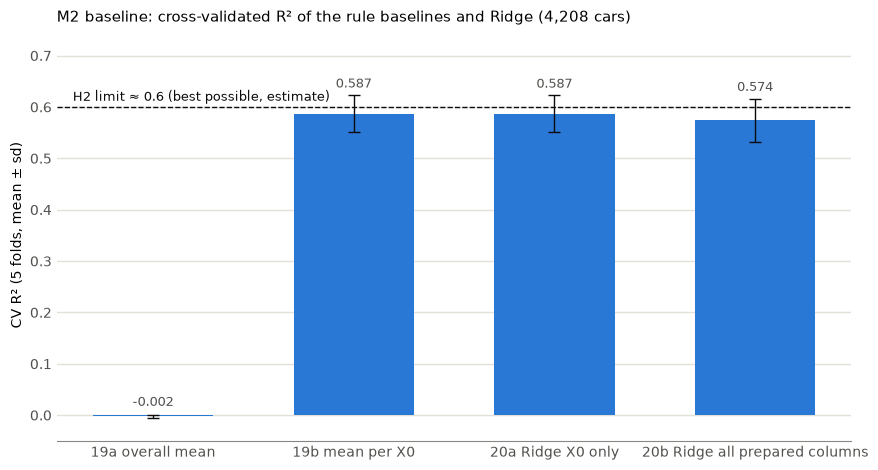

In [21]:
# Section 7, Step 21 (plan M2.4): Score table
# Uses: scores from Steps 19-20; winner_r2 from Step 6; H2 limit about 0.6 from Steps 5 and 9, R8/R37;
#       chart colours from Step 1
# H2 limit "about 0.6" (0.596 all cars, Step 5; 0.58 without the 265 s car, Step 9);
# a guide line, not a hard ceiling (R37)
h2_about = 0.6


def score_summary(model_scores):
    # Mean and sd of R² and RMSE over the 5 folds, one row per model (also used in Step 25)
    return pd.DataFrame({
        "CV R² mean": [s["r2"].mean() for s in model_scores.values()],
        "CV R² sd": [s["r2"].std(ddof=1) for s in model_scores.values()],
        "RMSE mean (s)": [s["rmse"].mean() for s in model_scores.values()],
        "RMSE sd (s)": [s["rmse"].std(ddof=1) for s in model_scores.values()],
    }, index=pd.Index(list(model_scores.keys()), name="model"))


score_table = score_summary(scores)
score_table["R² gain vs 19b"] = score_table["CV R² mean"] - score_table.loc["19b mean per X0", "CV R² mean"]
print(f"Kaggle winner {winner_r2} (Step 6; 1st place private leaderboard, external, verified D44)"
      " - text only, not compared in the chart")
display(score_table.round(3))

# ONE plot: CV R² per model (mean, with ± sd as a thin line), H2 limit "about 0.6" as a reference line
fig, ax = plt.subplots(figsize=(9, 4.8))
model_names = list(scores.keys())
r2_means, r2_sds = score_table["CV R² mean"].values, score_table["CV R² sd"].values
ax.bar(model_names, r2_means, color=blue, width=0.6)
ax.errorbar(model_names, r2_means, yerr=r2_sds, fmt="none", ecolor=ink, elinewidth=1, capsize=4)
for i, (m, s) in enumerate(zip(r2_means, r2_sds)):
    ax.text(i, max(m, 0) + s + 0.015, f"{m:.3f}", ha="center", fontsize=9, color=label_grey)
ax.axhline(h2_about, color=ink, linewidth=1, linestyle="--")
ax.text(-0.4, h2_about + 0.012, "H2 limit ≈ 0.6 (best possible, estimate)", ha="left", fontsize=9, color=ink)
ax.set_ylim(-0.05, 0.75)
ax.set_ylabel("CV R² (5 folds, mean ± sd)")
ax.set_title("M2 baseline: cross-validated R² of the rule baselines and Ridge (4,208 cars)", loc="left", fontsize=11)
ax.grid(axis="y", color=grid, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(muted)
ax.tick_params(colors=label_grey, length=0)
plt.tight_layout()
plt.show()

**Step 21 – reading the result**

| Model | CV R² (mean ± sd) | RMSE (mean ± sd) | R² gain vs 19b | Source |
|---|---|---|---|---|
| 19a overall mean | −0.002 ± 0.003 | 12.43 ± 0.29 s | −0.589 | Step 19 |
| 19b mean per X0 | **0.587 ± 0.036** | **7.97 ± 0.46 s** | – | Step 19 |
| 20a Ridge X0 only | **0.587 ± 0.035** | **7.97 ± 0.45 s** | 0.000 | Step 20 |
| 20b Ridge all prepared columns | 0.574 ± 0.042 | 8.09 ± 0.51 s | −0.013 | Step 20 |
| *Reference:* H2 limit | ≈ 0.6 (0.596 all cars; 0.58 without the 265 s car) | – | – | Steps 5 and 9, R8/R37 |
| *Reference:* Kaggle winner (1st place) | 0.5555 – **external, verified** (D44) | – | – | Step 6 |

- **Best M2 score: 0.587 (19b and 20a, tie).** The simple rule "average time per X0" and Ridge on X0 alone are equally good; the typical prediction error is about 8 s (instead of 12.4 s without any model).
- **We are at the H2 limit:** 0.587 is about 98 % of "about 0.6". The bars of 19b, 20a and 20b all touch the dashed line within one sd. There is little room left for any model on these columns – the rest of the differences in `y` is test-bench noise (H2).
- **More columns did not help a linear model:** 20b is 0.013 below X0 alone (R33, Step 20).
- **Kaggle winner 0.5555** (1st place, verified, D44) is only text here: it is an external number on Kaggle's hidden test cars (not our CV folds). It is not compared with our CV scores.

In simple words: the "average time per X0 code" rule is already about as good as the data allows (best possible R² from H2) – the remaining differences in test time are mostly chance, not the configuration.

Own decision: R49) 19b (mean per X0) is the M2 baseline to beat in M3, because it ties with 20a and is simpler to explain; R50) the chart shows the H2 limit as one dashed line at 0.6 ("about 0.6", R37) and leaves the winners' 0.55 out of the chart, because handover 16 asks for it only as text (external, to verify).

### Step 22 (plan M2.5): Final X0 table (documentation)

The rule baseline 19b predicts each car by the mean `y` of its X0 code. Here we build that table once from all 4,208 prepared cars, so the rule can be written down and reproduced without code (D35). It is documentation only: the scores of Steps 19–21 were learned on the training folds only and do not use this table.

In [22]:
# Section 7, Step 22 (plan M2.5): Final X0 table (documentation)
# Uses: train_m2, y_m2 from Step 17
# Built ONCE from all 4,208 prepared cars - documentation only, NOT used for any score
# (Steps 19-21 learned per training fold)
fallback_mean = y_m2.mean()                     # prediction for an X0 code not in the table (D25)
x0_final = (train_m2.groupby("X0")["y"]
            .agg(cars="size", mean_y="mean", sd_y="std", min_y="min", max_y="max")
            .sort_values(["cars", "mean_y"], ascending=[False, True]))
x0_final.columns = ["cars", "mean y (s)", "sd (s)", "min (s)", "max (s)"]

print("X0 codes in the table:", len(x0_final), "| cars:", int(x0_final["cars"].sum()),
      "| codes with only 1 car (no sd):", int((x0_final["cars"] == 1).sum()))
print(f"Unknown code -> overall mean of all 4,208 cars: {fallback_mean:.2f} s")
print("Shown: the 15 largest groups (full table in my_notes/m2_recipe_facts_v1.md)")
x0_final.head(15).round(2)

X0 codes in the table: 47 | cars: 4208 | codes with only 1 car (no sd): 3
Unknown code -> overall mean of all 4,208 cars: 100.63 s
Shown: the 15 largest groups (full table in my_notes/m2_recipe_facts_v1.md)


,cars,mean y (s),sd (s),min (s),max (s)
X0,,,,,
z,360,95.12,8.39,85.72,141.39
ak,349,112.55,7.55,101.86,154.87
y,323,93.51,7.80,83.49,134.81
ay,313,103.52,7.45,93.83,147.22
t,306,93.72,7.98,85.23,150.43
x,300,112.56,9.18,102.91,158.23
o,269,94.62,7.59,84.85,132.60
f,227,93.93,6.88,83.96,139.07
n,195,93.49,7.59,84.65,134.08


**Step 22 – reading the result**

| Check | Result |
|---|---|
| X0 codes in the table | **47** (all 4,208 prepared cars) |
| Cars in the 15 largest groups (shown above) | 3,540 of 4,208 (84 %) |
| Codes with fewer than 43 cars (rare, < 1 %, Step 10) | 29 codes, 453 cars |
| Codes with only 1 car (no sd) | 3: g, ac, ab |
| Fallback for an unknown code | **100.63 s** (mean `y` of all 4,208 cars) |
| Lowest / highest group mean | 76.19 s (bc) / 152.17 s (aa) |

- **The rule 19b in one table:** "find the car's X0 code, predict its mean `y`; if the code is not in the table, predict 100.63 s". The full table with all 47 codes is in `my_notes/m2_recipe_facts_v1.md` (out of git, D35).
- **The group means fall into the peaks of Step 7:** about 78 s (az), about 94 s (z, y, t, o, f, n, s), about 104 s (ay, aj) and about 112–117 s (ak, x, w, j, ap). That is why X0 alone explains about 59 % (Steps 19–21).
- **Documentation only:** this table uses all 4,208 cars at once. The CV scores of Steps 19–21 were learned on the training folds only and are not changed by it (no leak).

In simple words: this is the full table of the simple rule – one average test time per X0 code, and the overall average (100.63 s) for an X0 code not in the table.

Own decision: R52) the table is sorted by number of cars (largest first), because the notebook may show only 15 rows and the largest groups cover 84 % of the cars; R53) codes with 1 car keep their single value as mean (sd empty), because that is what rule 19b predicts for them.

## Section 8 (plan M3.1): Three algorithms

**Section 8 (Three algorithms) – Steps overview: compare three different algorithms – Ridge (M2, Step 20), Random Forest and XGBoost – on the same prepared data (Step 17) and the same 5 folds (Step 18); settings are tuned only inside the training folds (no leak); the rule 19b (mean per X0) is the score to beat (D32)**

| Step | Plan | Title | What it does |
|---|---|---|---|
| 23 | M3.1a | Random Forest | `RandomForestRegressor` (300 trees, random_state 42); inner CV grid max_depth (5, 10, None) × min_samples_leaf (5, 20); CV R² mean ± sd, RMSE, best settings per fold (edge?), run time |
| 24 | M3.1b | XGBoost | `XGBRegressor` (learning_rate 0.05, subsample 0.8, random_state 42); inner CV grid max_depth (2, 4) × n_estimators (200, 500); same report as Step 23 |
| 25 | M3.1c | Comparison | Table of 19a, 19b, 20a, 20b (from Steps 19–20, not re-run), 23, 24: CV R² mean ± sd, RMSE, gain vs 19b; ONE bar chart with a line at "about 0.6"; winners ≈ 0.55 as text only |

Stop rule: mean CV R² of Step 23 or 24 outside 0.50–0.70 (R8); run time above about 10 min is flagged. Source: handover 17 (D33, D35), plan v9 M3.1. Each step is run on its own with "do step k".

### Step 23 (plan M3.1a): Random Forest

A Random Forest is many decision trees, each trained on a random sample of cars; their predictions are averaged. Trees can find combinations of options (for example "X0 = az and X314 = 1") that a linear model like Ridge cannot. Tree depth and the minimum cars per leaf are chosen by an inner CV inside each training fold.

In [23]:
# Section 8, Step 23 (plan M3.1a): Random Forest
# Uses: X_m2, y_m2, text_keep, binary_keep from Step 17; kf from Step 18; add_score from Step 19; inner_cv from Step 20
def tuned_cv(model, grid):
    # One-hot fitted inside the pipeline on the training folds only (no leak);
    # settings chosen by inner CV inside each training fold
    prep = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), text_keep)], remainder="passthrough")
    pipe = Pipeline([("prep", prep), ("model", model)])
    search = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()}, cv=inner_cv, scoring="r2")
    start = perf_counter()
    res = cross_validate(search, X_m2, y_m2, cv=kf, scoring=["r2", "neg_root_mean_squared_error"],
                         return_estimator=True)
    best = [{k.replace("model__", ""): v for k, v in est.best_params_.items()} for est in res["estimator"]]
    return res["test_r2"], -res["test_neg_root_mean_squared_error"], best, perf_counter() - start


rf_grid = {"max_depth": [5, 10, None], "min_samples_leaf": [5, 20]}
r2_23, rmse_23, best_23, sec_23 = tuned_cv(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), rf_grid)
add_score("23 Random Forest", r2_23, rmse_23)

print(f"Run time: {sec_23 / 60:.1f} min (5 outer folds x 6 settings x 5 inner folds + refits)")
for setting, values in rf_grid.items():
    chosen = [b[setting] for b in best_23]
    print(f"Best {setting} per fold: {chosen} | at the edge of the grid ({values[0]} or {values[-1]}): "
          f"{sum(c in (values[0], values[-1]) for c in chosen)} of 5 folds")
print(f"23: CV R² {r2_23.mean():.3f} ± {r2_23.std(ddof=1):.3f} | RMSE {rmse_23.mean():.2f} s"
      f" | within 0.50-0.70: {0.50 <= r2_23.mean() <= 0.70}"
      f" | gain vs 19b: {r2_23.mean() - scores['19b mean per X0']['r2'].mean():+.3f}")
pd.DataFrame({"23 R²": r2_23, "23 RMSE (s)": rmse_23, "19b R² (Step 19)": scores["19b mean per X0"]["r2"]},
             index=pd.RangeIndex(1, 6, name="fold")).round(3)

Run time: 3.2 min (5 outer folds x 6 settings x 5 inner folds + refits)
Best max_depth per fold: [5, 5, 5, 5, 5] | at the edge of the grid (5 or None): 5 of 5 folds
Best min_samples_leaf per fold: [5, 5, 5, 5, 20] | at the edge of the grid (5 or 20): 5 of 5 folds
23: CV R² 0.589 ± 0.038 | RMSE 7.95 s | within 0.50-0.70: True | gain vs 19b: +0.002


,23 R²,23 RMSE (s),19b R² (Step 19)
fold,,,
1,0.572,8.199,0.554
2,0.542,8.293,0.556
3,0.638,7.381,0.634
4,0.617,7.510,0.615
5,0.578,8.355,0.577


**Step 23 – reading the result**

| Fold | 23 R² | 23 RMSE | 19b R² (Step 19) |
|---|---|---|---|
| 1 | 0.572 | 8.20 s | 0.554 |
| 2 | 0.542 | 8.29 s | 0.556 |
| 3 | 0.638 | 7.38 s | 0.634 |
| 4 | 0.617 | 7.51 s | 0.615 |
| 5 | 0.578 | 8.36 s | 0.577 |
| **Mean ± sd** | **0.589 ± 0.038** | **7.95 s** | 0.587 ± 0.036 |

| Setting | Best per fold | At the edge of the grid |
|---|---|---|
| max_depth (5, 10, None) | 5, 5, 5, 5, 5 | **5 of 5 at 5** (the shallowest value) |
| min_samples_leaf (5, 20) | 5, 5, 5, 5, 20 | always an edge (only 2 values); 4 of 5 chose 5 |
| Run time | 3.1 min | below the 10 min flag |

- **Stop rule (R8):** mean CV R² 0.589 is within 0.50–0.70 – no stop.
- **Random Forest = rule 19b, practically:** +0.002 over the mean per X0 (0.589 vs 0.587), better in 4 of 5 folds but worse in fold 2 (0.542 vs 0.556). The gain is far smaller than the fold-to-fold sd (0.038), so it is **no real improvement**.
- **Shallow trees win:** every fold picks the shallowest depth (5). Deeper trees learn more noise of single cars; the forest mainly needs the few splits that separate the X0 groups – the same information as rule 19b.
- **Edge:** max_depth is at the lowest value in all folds, so an even shallower tree (e.g. 3) might score the same or slightly better. A wider grid is not in handover 17 and is not done here.

In simple words: 300 decision trees that may look at all 310 columns end up with about the same prediction as "average time per X0 code" – the other columns do not hold more usable information.

Own decision: R54) a gain below one fold sd (here +0.002 vs sd 0.038) is read as "no real improvement", because the fold-to-fold variation is about 20 times larger than the gain; R55) max_depth at the edge (5 in 5 of 5 folds) is only reported, not tuned further, because handover 17 fixes the grid.

### Step 24 (plan M3.1b): XGBoost

XGBoost builds small trees one after another; each new tree corrects the errors of the trees before it (gradient boosting). The tree depth and the number of trees are chosen by an inner CV inside each training fold.

In [24]:
# Section 8, Step 24 (plan M3.1b): XGBoost
# Uses: tuned_cv from Step 23; X_m2, y_m2 from Step 17; kf from Step 18; add_score, scores from Step 19;
#       inner_cv from Step 20
import xgboost  # check first (D34): installed by Mohammad
from xgboost import XGBRegressor
print(f"xgboost {xgboost.__version__} imported")

xgb_grid = {"max_depth": [2, 4], "n_estimators": [200, 500]}
r2_24, rmse_24, best_24, sec_24 = tuned_cv(XGBRegressor(learning_rate=0.05, subsample=0.8, random_state=42), xgb_grid)
add_score("24 XGBoost", r2_24, rmse_24)

print(f"Run time: {sec_24 / 60:.1f} min (5 outer folds x 4 settings x 5 inner folds + refits)")
for setting, values in xgb_grid.items():
    chosen = [b[setting] for b in best_24]
    print(f"Best {setting} per fold: {chosen} | at the edge of the grid ({values[0]} or {values[-1]}): "
          f"{sum(c in (values[0], values[-1]) for c in chosen)} of 5 folds")
print(f"24: CV R² {r2_24.mean():.3f} ± {r2_24.std(ddof=1):.3f} | RMSE {rmse_24.mean():.2f} s"
      f" | within 0.50-0.70: {0.50 <= r2_24.mean() <= 0.70}"
      f" | gain vs 19b: {r2_24.mean() - scores['19b mean per X0']['r2'].mean():+.3f}")
pd.DataFrame({"24 R²": r2_24, "24 RMSE (s)": rmse_24, "23 R² (Step 23)": r2_23,
              "19b R² (Step 19)": scores["19b mean per X0"]["r2"]},
             index=pd.RangeIndex(1, 6, name="fold")).round(3)

xgboost 3.4.1 imported
Run time: 0.7 min (5 outer folds x 4 settings x 5 inner folds + refits)
Best max_depth per fold: [2, 2, 2, 2, 2] | at the edge of the grid (2 or 4): 5 of 5 folds
Best n_estimators per fold: [200, 200, 200, 200, 200] | at the edge of the grid (200 or 500): 5 of 5 folds
24: CV R² 0.593 ± 0.037 | RMSE 7.91 s | within 0.50-0.70: True | gain vs 19b: +0.006


,24 R²,24 RMSE (s),23 R² (Step 23),19b R² (Step 19)
fold,,,,
1,0.572,8.195,0.572,0.554
2,0.551,8.211,0.542,0.556
3,0.644,7.314,0.638,0.634
4,0.616,7.526,0.617,0.615
5,0.583,8.308,0.578,0.577


**Step 24 – reading the result**

| Fold | 24 R² | 24 RMSE | 23 R² (Step 23) | 19b R² (Step 19) |
|---|---|---|---|---|
| 1 | 0.572 | 8.20 s | 0.572 | 0.554 |
| 2 | 0.551 | 8.21 s | 0.542 | 0.556 |
| 3 | 0.644 | 7.31 s | 0.638 | 0.634 |
| 4 | 0.616 | 7.53 s | 0.617 | 0.615 |
| 5 | 0.583 | 8.31 s | 0.578 | 0.577 |
| **Mean ± sd** | **0.593 ± 0.037** | **7.91 s** | 0.589 ± 0.038 | 0.587 ± 0.036 |

| Setting | Best per fold | At the edge of the grid |
|---|---|---|
| max_depth (2, 4) | 2, 2, 2, 2, 2 | **5 of 5 at 2** (the shallower value) |
| n_estimators (200, 500) | 200, 200, 200, 200, 200 | **5 of 5 at 200** (the fewer trees) |
| Run time | 0.7 min | below the 10 min flag |

- **Check:** `import xgboost` works (version 3.4.1, D34).
- **Stop rule (R8):** mean CV R² 0.593 is within 0.50–0.70 – no stop.
- **XGBoost = rule 19b, practically:** +0.006 over the mean per X0 (0.593 vs 0.587), better in 4 of 5 folds but worse in fold 2 (0.551 vs 0.556). The gain is about 6 times smaller than the fold-to-fold sd (0.037), so by R54 it is **no real improvement**. Against the Random Forest (Step 23) the difference is +0.004 – also within the noise.
- **The simplest setting wins:** every fold picks the smallest trees (depth 2) and the fewer trees (200). The model needs only a few simple splits – mainly the X0 groups, the same information as rule 19b.
- **Edge:** both settings sit at the low edge in all folds, so even smaller settings (e.g. depth 1 or 100 trees) might score the same. A wider grid is not in handover 17 and is not done here.

In simple words: a team of small trees that keep correcting each other ends up with about the same prediction as "average time per X0 code" – like the Random Forest in Step 23.

Own decision: R56) the two edge results (depth 2 and 200 trees in 5 of 5 folds) are only reported, not tuned further, because handover 17 fixes the grid (same rule as R55).

### Step 25 (plan M3.1c): Comparison

We put all six models side by side – the two rule baselines, Ridge (two variants), Random Forest and XGBoost – with the same score (CV R² and RMSE on the same 5 folds) and compare them with the H2 limit (about 0.6) in one bar chart.

M2 rows (19a, 19b, 20a, 20b) equal Step 21: True
Kaggle winner 0.5555 (Step 6; 1st place private leaderboard, external, verified D44) - text only, not compared in the chart


,CV R² mean,CV R² sd,RMSE mean (s),RMSE sd (s),R² gain vs 19b,folds better than 19b
model,,,,,,
19a overall mean,-0.002,0.003,12.426,0.293,-0.589,0
19b mean per X0,0.587,0.036,7.972,0.460,0.000,0
20a Ridge X0 only,0.587,0.035,7.971,0.453,0.000,2
20b Ridge all prepared columns,0.574,0.042,8.091,0.509,-0.013,1
23 Random Forest,0.589,0.038,7.947,0.464,0.002,4
24 XGBoost,0.593,0.037,7.911,0.456,0.006,4


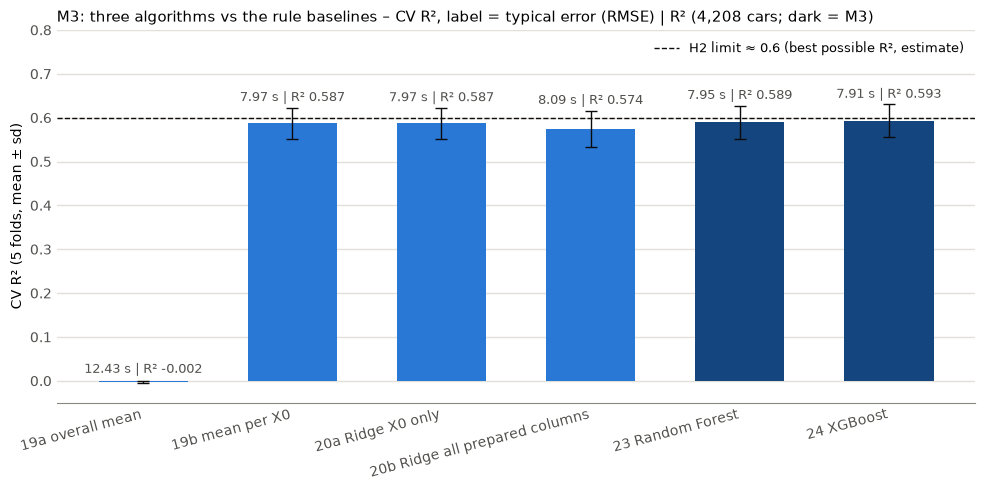

In [25]:
# Section 8, Step 25 (plan M3.1c): Comparison
# Uses: scores from Steps 19, 20, 23, 24 – not re-run; score_table, score_summary, h2_about from Step 21;
#       winner_r2 from Step 6; chart colours from Step 1
comp = score_summary(scores)
comp["R² gain vs 19b"] = comp["CV R² mean"] - comp.loc["19b mean per X0", "CV R² mean"]
comp["folds better than 19b"] = [int((s["r2"] > scores["19b mean per X0"]["r2"]).sum()) for s in scores.values()]

# Check: the four M2 rows must equal the Step 21 table (taken from the stored scores, not re-run)
same_m2 = np.allclose(comp.loc[score_table.index, score_table.columns].values, score_table.values)
assert same_m2, "M2 rows differ from Step 21 - stop and report"
print("M2 rows (19a, 19b, 20a, 20b) equal Step 21:", same_m2)
print(f"Kaggle winner {winner_r2} (Step 6; 1st place private leaderboard, external, verified D44)"
      " - text only, not compared in the chart")
display(comp.round(3))

# ONE plot: CV R² per model (mean, ± sd as a thin line); label on every bar = typical error in seconds first,
# R² next to it (D39); M3 models (23, 24) in a darker blue (R57); H2 limit "about 0.6" as a dashed line,
# named in the legend so no label sits on the bars
fig, ax = plt.subplots(figsize=(10, 5))
model_names = list(comp.index)
r2_means, r2_sds, rmse_means = comp["CV R² mean"].values, comp["CV R² sd"].values, comp["RMSE mean (s)"].values
ax.bar(model_names, r2_means, color=[blue_dark if n.startswith(("23", "24")) else blue for n in model_names], width=0.6)
ax.errorbar(model_names, r2_means, yerr=r2_sds, fmt="none", ecolor=ink, elinewidth=1, capsize=4)
for i, (m, s, e) in enumerate(zip(r2_means, r2_sds, rmse_means)):
    ax.text(i, max(m, 0) + s + 0.015, f"{e:.2f} s | R² {m:.3f}", ha="center", fontsize=9, color=label_grey)
ax.axhline(h2_about, color=ink, linewidth=1, linestyle="--", label="H2 limit ≈ 0.6 (best possible R², estimate)")
ax.legend(loc="upper right", frameon=False, fontsize=9)
ax.set_ylim(-0.05, 0.8)
ax.set_ylabel("CV R² (5 folds, mean ± sd)")
ax.set_title("M3: three algorithms vs the rule baselines – CV R², label = typical error (RMSE) | R² "
             "(4,208 cars; dark = M3)", loc="left", fontsize=11)
ax.grid(axis="y", color=grid, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(muted)
ax.tick_params(colors=label_grey, length=0)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Step 25 – reading the result**

| Model | CV R² (mean ± sd) | RMSE (mean ± sd) | R² gain vs 19b | Folds better than 19b | Source |
|---|---|---|---|---|---|
| 19a overall mean | −0.002 ± 0.003 | 12.43 ± 0.29 s | −0.589 | 0 of 5 | Step 19 |
| 19b mean per X0 (baseline to beat, R49) | 0.587 ± 0.036 | 7.97 ± 0.46 s | – | – | Step 19 |
| 20a Ridge X0 only | 0.587 ± 0.035 | 7.97 ± 0.45 s | 0.000 | 2 of 5 | Step 20 |
| 20b Ridge all prepared columns | 0.574 ± 0.042 | 8.09 ± 0.51 s | −0.013 | 1 of 5 | Step 20 |
| 23 Random Forest | 0.589 ± 0.038 | 7.95 ± 0.46 s | +0.002 | 4 of 5 | Step 23 |
| 24 XGBoost | **0.593 ± 0.037** | **7.91 ± 0.46 s** | **+0.006** | 4 of 5 | Step 24 |
| *Reference:* H2 limit | ≈ 0.6 (dashed line) | – | – | – | Steps 5 and 9, R8/R37 |
| *Reference:* Kaggle winner (1st place) | 0.5555 – **external, verified** (D44) | – | – | – | Step 6 |

- **How to read the chart:** the bar height is CV R² (the score Kaggle uses); the label on each bar shows the typical error in seconds first and R² next to it, e.g. "7.97 s | R² 0.587" for 19b (D39). The dashed line is the H2 limit "about 0.6", named in the legend.
- **Check:** the four M2 rows are taken from the stored scores (not re-run) and equal the Step 21 table exactly.
- **Highest score: XGBoost 0.593**, then Random Forest 0.589 and rule 19b 0.587. The whole spread between the best four models (0.574–0.593) is smaller than one fold sd (about 0.037), so by R54 **none of the three algorithms is really better than "average time per X0"**. XGBoost predicts on average 0.06 s more precisely (7.91 s vs 7.97 s) – practically nothing for a test that takes about 100 s.
- **At the H2 limit:** all bars of 19b, 20a, 20b, 23 and 24 reach the dashed line "about 0.6" within one sd. XGBoost reaches about 99 % of it. This supports H2: the remaining differences in `y` are mostly test-bench noise, not information in the option columns.
- **Three different algorithms, same answer:** a linear model (Ridge), averaging trees (Random Forest) and boosted trees (XGBoost) all end at about 0.59. Both tree models choose their simplest settings (Steps 23–24), so they do not find useful combinations of options beyond X0.
- **Kaggle winner 0.5555** (1st place, verified, D44) is only text: it was measured on Kaggle's hidden test cars, not on our CV folds.

In simple words: three very different models – one straight-line formula (Ridge), one with 300 trees voting (Random Forest), one with trees learning from each other's mistakes (XGBoost) – all predict the test time equally well, and all about as well as the plain "average time per X0 code". The rest of the variation is chance, not the configuration.

Own decision: R57) the M3 bars (23, 24) are drawn in a darker blue than the M2 bars, because the chart should show at a glance which models are new in M3; R58) the table adds a column "folds better than 19b", because a mean gain this small only means something if it is also consistent across folds (it is 4 of 5 for both tree models, but still within the noise).

## Section 9 (plan M3.2): Error analysis

**Section 9 (Error analysis) – Steps overview: where does the preferred model 20a Ridge X0 only (D40) make its biggest errors – single cars, H2 twin groups, long tests, or certain X0 codes? Same prepared data (Step 17), same 5 folds (Step 18); every car is predicted by the model that did not see it (no leak); error in seconds first, R² next to it (D39)**

| Step | Plan | Title | What it does |
|---|---|---|---|
| 26 | M3.2a | Errors per car | Out-of-fold predictions of 20a; error per car (real − predicted, s); 10 worst cars; share within ±5 s and ±10 s; worst cars in twin groups (Step 3) or long tests (Step 8)? Check: RMSE = Step 20a (7.97 s) |
| 27 | M3.2b | Errors per X0 code | Cars and mean absolute error (s) per X0 code; ONE chart (sorted, car count shown); 5 worst codes; do small groups dominate? |

Source: handover 20 (D41), plan v10 M3.2. Each step is run on its own with "do step k". Model choice (M3.4) and Kaggle submission (M3.3) are not part of this section.

### Step 26 (plan M3.2a): Errors per car

Each car gets a prediction from the 20a model (Ridge on X0 only) that was trained on the other four folds, so no car is predicted by a model that saw it. The error per car (real − predicted, in seconds) shows how often the model is close and which cars it misses badly.

In [26]:
# Section 9, Step 26 (plan M3.2a): Errors per car – Ridge X0 only
# Uses: train from Step 1; in_group from Step 3; y, q3, iqr from Step 8; train_m2, X_m2, y_m2 from Step 17;
#       kf, folds from Step 18; alpha_grid, inner_cv, rmse_20a from Step 20
# Same model as 20a: one-hot X0 inside the pipeline, alpha by inner CV inside each training fold;
# each car is predicted by the model that did NOT see it
prep_x0 = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), ["X0"])], remainder="drop")
search_20a = GridSearchCV(Pipeline([("prep", prep_x0), ("ridge", Ridge())]), {"ridge__alpha": alpha_grid},
                          cv=inner_cv, scoring="r2")
oof_20a = cross_val_predict(search_20a, X_m2[["X0"]], y_m2, cv=kf)

# Check: the RMSE per fold must equal Step 20a
rmse_check = np.array([root_mean_squared_error(y_m2.iloc[va], oof_20a[va]) for _, va in folds])
assert np.allclose(rmse_check, rmse_20a), "out-of-fold errors differ from Step 20a - stop and report"
print(f"Check: RMSE mean of the 5 folds {rmse_check.mean():.2f} s = Step 20a {rmse_20a.mean():.2f} s: True"
      f" | all 4,208 cars pooled: {root_mean_squared_error(y_m2, oof_20a):.2f} s")

# Error per car (real - predicted); labels from Steps 3 and 8 matched by car ID (those steps used all 4,209 cars)
long_limit = q3 + 1.5 * iqr                                  # Step 8: "cars above 1.5 × IQR"
twin_ids = set(train.loc[in_group, "ID"])
long_ids = set(train.loc[y > long_limit, "ID"])
err = pd.DataFrame({"ID": train_m2["ID"], "X0": train_m2["X0"], "real (s)": y_m2, "predicted (s)": oof_20a})
err["error (s)"] = err["real (s)"] - err["predicted (s)"]
err["abs error (s)"] = err["error (s)"].abs()
err["twin group (Step 3)"] = err["ID"].isin(twin_ids)
err["long test (Step 8)"] = err["ID"].isin(long_ids)
print(f"Long tests (y > {long_limit:.2f} s, Step 8): {len(long_ids)} of 4,209 cars, "
      f"{int(err['long test (Step 8)'].sum())} of them in the 4,208 cars")

within = {f"within ±{k} s": (err["abs error (s)"] <= k).mean() for k in (5, 10)}
print(" | ".join(f"{k}: {v:.1%}" for k, v in within.items()))

# Are the worst cars mostly twins or long tests? Worst 10 and worst 1 % (42 cars) vs all cars
ranked = err.sort_values("abs error (s)", ascending=False)
share = pd.DataFrame({name: [part["twin group (Step 3)"].mean(), part["long test (Step 8)"].mean(),
                             (part["error (s)"] > 0).mean()]
                      for name, part in [("worst 10", ranked.head(10)), ("worst 1 % (42)", ranked.head(42)),
                                         ("all 4,208", err)]},
                     index=["share in a twin group", "share long test", "share real > predicted"])
display((share * 100).round(1).astype(str) + " %")

worst10 = ranked.head(10).reset_index(drop=True)
worst10.index = worst10.index + 1
worst10[["ID", "X0", "real (s)", "predicted (s)", "error (s)", "twin group (Step 3)", "long test (Step 8)"]].round(2)

Check: RMSE mean of the 5 folds 7.97 s = Step 20a 7.97 s: True | all 4,208 cars pooled: 7.98 s
Long tests (y > 136.30 s, Step 8): 50 of 4,209 cars, 49 of them in the 4,208 cars
within ±5 s: 62.1% | within ±10 s: 90.8%


,worst 10,worst 1 % (42),"all 4,208"
share in a twin group,20.0 %,11.9 %,12.2 %
share long test,100.0 %,54.8 %,1.2 %
share real > predicted,100.0 %,100.0 %,34.2 %


,ID,X0,real (s),predicted (s),error (s),twin group (Step 3),long test (Step 8)
1,2903,ai,167.45,94.06,73.39,False,True
2,6273,aj,165.52,104.23,61.29,True,True
3,2511,s,152.32,92.07,60.25,False,True
4,505,t,150.43,93.69,56.74,False,True
5,1784,aj,158.53,103.39,55.14,False,True
6,2396,j,160.87,111.69,49.18,False,True
7,5471,x,158.23,111.76,46.47,True,True
8,5706,z,141.39,94.98,46.41,False,True
9,6873,f,139.07,93.54,45.53,False,True
10,7500,x,155.62,111.76,43.86,False,True


**Step 26 – reading the result**

| Check / measure | Result |
|---|---|
| Typical error (RMSE), mean of the 5 folds | **7.97 s** = Step 20a (check passed); all 4,208 cars pooled: 7.98 s |
| Cars predicted within ±5 s | **62.1 %** |
| Cars predicted within ±10 s | **90.8 %** |
| Long tests (> 136.30 s, Step 8) | 49 of the 4,208 cars (1.2 %) |

| Share | Worst 10 | Worst 1 % (42 cars) | All 4,208 cars |
|---|---|---|---|
| in an H2 twin group (Step 3) | 20 % | 11.9 % | 12.2 % |
| long test (Step 8) | **100 %** | **54.8 %** | 1.2 % |
| real time longer than predicted | 100 % | 100 % | 34.2 % |

The 10 worst cars (table above, errors 43.9–73.4 s) are all long tests between 139 s and 167 s; the model predicted 92–112 s for them – the usual time of their X0 group.

- **The big errors are the long tests:** all 10 worst cars and more than half of the worst 1 % are among the 49 long tests – only 1.2 % of all cars. Every one of the 42 worst cars took longer than predicted, none was faster. So the model never "over-predicts" badly; it misses cars that suddenly take 40–70 s longer than others with the same X0.
- **Twin groups play no special role:** the share of twins among the worst 1 % (11.9 %) equals their share among all cars (12.2 %). The 2 of 10 in the worst 10 are too few to mean anything.
- **For most cars the model is close:** 9 of 10 cars are within ±10 s, 6 of 10 within ±5 s. The RMSE of about 8 s is pushed up by the few very long tests.
- **Link to H2:** X0 says nothing about why a car takes 150 s instead of 95 s. This fits H2 – the long tests look like test-bench events, not like an effect of the options.

In simple words: the "average time per X0 code" rule is close (within ±10 s) for 9 of 10 cars; its big misses are the few cars with very long tests – and the configuration cannot tell which cars that will be.

Note: the table shows car IDs of the public Kaggle teaching dataset (no personal data), as handover 20 asks.

Own decision: R59) "long test" = longer than Q3 + 1.5 × IQR (136.30 s), the limit of Step 8, because Step 8 named this group; it is 49 of the 4,208 cars; R60) besides the worst 10, the worst 1 % (42 cars) is shown, because 10 cars are too few for a stable share; R61) the check compares with the mean of the 5 per-fold RMSE values (7.97 s, how Step 20a reports it); the pooled value over all cars (7.98 s) is shown next to it.

### Step 27 (plan M3.2b): Errors per X0 code

The errors of Step 26 are grouped by X0 code: number of cars and mean absolute error in seconds per code. One chart shows which codes are hardest to predict and whether these are small groups with few cars.

X0 codes: 47 | mean abs error over all 4,208 cars: 5.33 s
Rare codes among the 5 worst: 5 of 5 | among the 10 worst: 9 of 10 | rank correlation cars vs mean abs error (Spearman): -0.25


,codes,cars,mean abs error (s)
common (≥ 43 cars),18,3755,5.29
rare (< 43 cars),29,453,5.72


,cars,mean abs error (s),mean error real − predicted (s),long tests (Step 8),rare (< 43 cars)
X0,,,,,
aa,2,33.89,4.53,1,True
k,11,14.33,1.07,0,True
ac,1,13.13,-13.13,0,True
ab,1,10.21,10.21,0,True
g,1,8.85,8.85,0,True


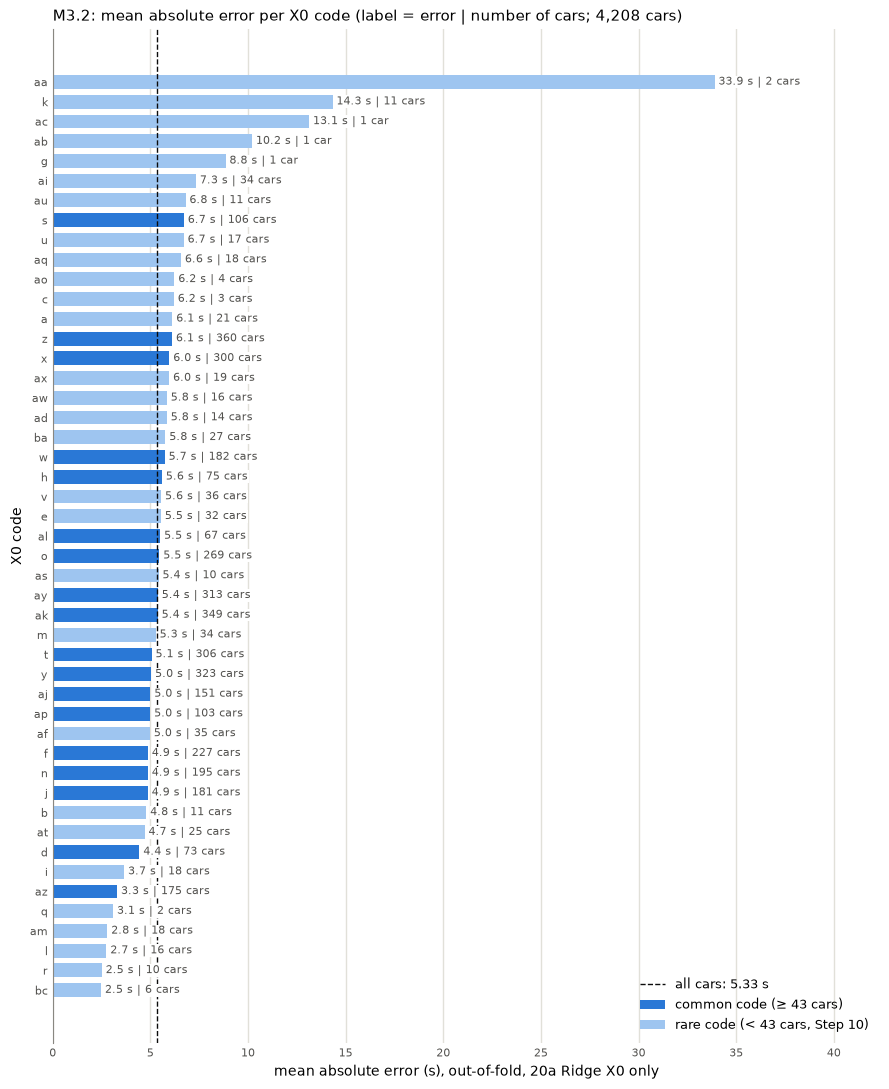

In [27]:
# Section 9, Step 27 (plan M3.2b): Errors per X0 code
# Uses: err from Step 26; rare limit 43 cars from Step 10; chart colours from Step 1
rare_code_limit = 43   # Step 10: fewer than 43 cars (< 1 %) = rare code

per_x0 = (err.groupby("X0")
             .agg(cars=("ID", "size"), mae=("abs error (s)", "mean"), mean_error=("error (s)", "mean"),
                  long_tests=("long test (Step 8)", "sum"))
             .rename(columns={"mae": "mean abs error (s)", "mean_error": "mean error real − predicted (s)",
                              "long_tests": "long tests (Step 8)"})
             .sort_values("mean abs error (s)", ascending=False))
per_x0["rare (< 43 cars)"] = per_x0["cars"] < rare_code_limit
overall_mae = err["abs error (s)"].mean()
print(f"X0 codes: {len(per_x0)} | mean abs error over all 4,208 cars: {overall_mae:.2f} s")

# Do small groups dominate? Rare vs common codes, and the link between group size and error
size_cmp = pd.DataFrame({
    "codes": per_x0.groupby("rare (< 43 cars)").size(),
    "cars": per_x0.groupby("rare (< 43 cars)")["cars"].sum(),
    "mean abs error (s)": (err.assign(rare=err["X0"].map(per_x0["rare (< 43 cars)"]))
                           .groupby("rare")["abs error (s)"].mean()),
}).rename(index={False: "common (≥ 43 cars)", True: "rare (< 43 cars)"})
top5 = per_x0.head(5)
print(f"Rare codes among the 5 worst: {int(top5['rare (< 43 cars)'].sum())} of 5"
      f" | among the 10 worst: {int(per_x0.head(10)['rare (< 43 cars)'].sum())} of 10"
      f" | rank correlation cars vs mean abs error (Spearman): "
      f"{per_x0['cars'].corr(per_x0['mean abs error (s)'], method='spearman'):.2f}")
display(size_cmp.round(2))
display(top5.round(2))

# ONE plot: mean abs error per X0 code (sorted), car count as label; rare codes in a lighter blue;
# overall mean as a dashed line
plot_df = per_x0.iloc[::-1]   # largest error at the top
fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(plot_df.index, plot_df["mean abs error (s)"],
        color=[blue_light if r else blue for r in plot_df["rare (< 43 cars)"]], height=0.7)
for i, (v, n) in enumerate(zip(plot_df["mean abs error (s)"], plot_df["cars"])):
    # white box: the dashed line does not cross the label
    ax.text(v + 0.2, i, f"{v:.1f} s | {n} car{'s' if n > 1 else ''}", va="center", fontsize=8, color=label_grey,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax.axvline(overall_mae, color=ink, linewidth=1, linestyle="--", label=f"all cars: {overall_mae:.2f} s")
ax.bar(0, 0, color=blue, label="common code (≥ 43 cars)")
ax.bar(0, 0, color=blue_light, label="rare code (< 43 cars, Step 10)")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_xlim(0, plot_df["mean abs error (s)"].max() * 1.25)
ax.set_xlabel("mean absolute error (s), out-of-fold, 20a Ridge X0 only")
ax.set_ylabel("X0 code")
ax.set_title("M3.2: mean absolute error per X0 code (label = error | number of cars; 4,208 cars)",
             loc="left", fontsize=11)
ax.grid(axis="x", color=grid, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "bottom"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(muted)
ax.tick_params(colors=label_grey, length=0, labelsize=8)
plt.tight_layout()
plt.show()

**Step 27 – reading the result**

| Group | X0 codes | Cars | Mean absolute error |
|---|---|---|---|
| All cars | 47 | 4,208 | **5.33 s** |
| Common codes (≥ 43 cars, Step 10) | 18 | 3,755 | 5.29 s |
| Rare codes (< 43 cars) | 29 | 453 | 5.72 s |

| 5 worst X0 codes | Mean absolute error | Cars | Long tests (Step 8) |
|---|---|---|---|
| aa | **33.9 s** | 2 | 1 |
| k | 14.3 s | 11 | 0 |
| ac | 13.1 s | 1 | 0 |
| ab | 10.2 s | 1 | 0 |
| g | 8.8 s | 1 | 0 |

- **The worst codes are all small groups:** all 5 worst codes are rare (1–11 cars), and 9 of the 10 worst are rare. Three of them have only 1 car. That car is never in its own training fold, so the model predicts it from the other cars, without its X0 mean (unknown code → all one-hot columns 0, D25).
- **But small groups do not dominate the total error:** the rare codes hold only 453 cars (11 %), and their mean absolute error (5.72 s) is only 0.4 s above that of the common codes (5.29 s). The rank correlation between group size and error is weak (−0.25).
- **Small groups sit at both ends:** the 5 best codes (bc, r, l, am, q: 2.5–3.1 s) are also rare. With few cars, the mean error per code depends on chance – a few cars can make a code look very good or very bad.
- **The common codes are close together:** 3.3 s (az) to 6.7 s (s). No large X0 group is clearly badly predicted.

In simple words: the "average time per X0 code" rule works about equally well for all common X0 codes (errors 3–7 s). The extreme values belong to X0 codes with only one or two cars – there the average is based on too few cars to say much.

Own decision: R62) "rare code" = fewer than 43 cars (< 1 %), the limit of Step 10, shown in a lighter blue, because this answers "do small groups dominate?" with an existing limit; R63) the chart shows all 47 codes as horizontal bars (sorted, label = error | cars), while the table shows only the 5 worst, because the notebook shows at most 15 table rows.

## Section 10 (plan M3.3): Kaggle submission

**Section 10 (Kaggle submission) – Steps overview: fit the final model 20a Ridge X0 only (D43) on all 4,208 prepared training cars and write one prediction per test car into a submission file for a manual upload. No upload and no network call in the notebook (D45)**

| Step | Plan | Title | What it does |
|---|---|---|---|
| 28 | M3.3 | Submission file – Ridge X0 only | Alpha from the Step 20 grid with the same 5 folds (Step 18); fit on all 4,208 cars; predict all test cars from `data/test.csv`; checks (rows, ID order, no missing values, range, unseen X0 codes vs Step 12); writes `data/submission_ridge_x0_v1.csv` (`ID,y`) |

Source: handover 21 (D45), plan v10 M3.3. The file stays in `data/` and out of git (D6). The upload to Kaggle is done by Mohammad by hand.

### Step 28 (plan M3.3): Submission file – Ridge X0 only

The final model 20a (one-hot X0, unknown codes → all 0, Ridge) is fitted once on all 4,208 prepared training cars, with alpha chosen by the same 5 folds as before. It then predicts the test time for every car in `data/test.csv` – no test car is dropped – and the predictions are saved as `ID,y` for the Kaggle upload.

In [28]:
# Section 10, Step 28 (plan M3.3): Submission file – Ridge X0 only
# Uses: X_m2, y_m2 from Step 17; kf from Step 18; alpha_grid from Step 20; unseen from Step 12
# Final model 20a (D43): one-hot X0 (unknown codes -> all 0, R21), Ridge;
# alpha chosen on all 4,208 cars with the same 5 folds (kf, Step 18)
pipe_28 = Pipeline([
    ("prep", ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), ["X0"])], remainder="drop")),
    ("ridge", Ridge()),
])
final_28 = GridSearchCV(pipe_28, {"ridge__alpha": alpha_grid}, cv=kf, refit="r2",
                        scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"}).fit(X_m2[["X0"]], y_m2)
alpha_28 = final_28.best_params_["ridge__alpha"]
alpha_table = pd.DataFrame({"CV RMSE (s)": -final_28.cv_results_["mean_test_rmse"],
                            "CV R²": final_28.cv_results_["mean_test_r2"]},
                           index=pd.Index(alpha_grid, name="alpha")).round(3)
print(f"Chosen alpha: {alpha_28} | at the edge of the grid ({alpha_grid[0]} or {alpha_grid[-1]}): "
      f"{alpha_28 in (alpha_grid[0], alpha_grid[-1])}")

# Predict every test car (the 265 s rule of D23 applies to training only)
test_28 = pd.read_csv("data/test.csv")
submission = pd.DataFrame({"ID": test_28["ID"], "y": final_28.predict(test_28[["X0"]])})

# Checks
unseen_28 = ~test_28["X0"].isin(set(X_m2["X0"]))                     # X0 code never seen in the 4,208 training cars
intercept_28 = final_28.best_estimator_["ridge"].intercept_
assert len(submission) == len(test_28) == 4209, "row count differs from test.csv"
assert submission["ID"].equals(test_28["ID"]), "IDs differ from test.csv or are in another order"
assert submission["ID"].is_unique and submission["y"].notna().all(), "duplicate IDs or missing predictions"
assert unseen_28.sum() == unseen.loc["X0", "test cars affected"], "unseen X0 cars differ from Step 12"
assert np.allclose(submission.loc[unseen_28, "y"], intercept_28), "unseen X0 cars do not get the intercept"

out_28 = Path("data/submission_ridge_x0_v1.csv")
submission.to_csv(out_28, index=False)
back = pd.read_csv(out_28)
assert back.columns.tolist() == ["ID", "y"] and back.shape == (4209, 2), "written file is not ID,y with 4,209 rows"

print(f"Written: {out_28} | {back.shape[0]} rows | columns {back.columns.tolist()}")
print(f"Checks passed: rows = test.csv ({len(test_28)}), IDs identical and same order, no missing values, "
      f"{int(unseen_28.sum())} unseen X0 cars = Step 12")
print(f"Predictions (s): min {submission['y'].min():.2f} | mean {submission['y'].mean():.2f}"
      f" | max {submission['y'].max():.2f}"
      f" | training y_m2: min {y_m2.min():.2f} | mean {y_m2.mean():.2f} | max {y_m2.max():.2f}")
print(f"Unseen X0 codes {sorted(test_28.loc[unseen_28, 'X0'])} -> every one gets the intercept {intercept_28:.2f} s")
alpha_table

Chosen alpha: 0.1 | at the edge of the grid (0.1 or 100): True
Written: data/submission_ridge_x0_v1.csv | 4209 rows | columns ['ID', 'y']
Checks passed: rows = test.csv (4209), IDs identical and same order, no missing values, 6 unseen X0 cars = Step 12
Predictions (s): min 76.63 | mean 100.93 | max 118.55 | training y_m2: min 72.11 | mean 100.63 | max 169.91
Unseen X0 codes ['ae', 'ag', 'an', 'av', 'bb', 'p'] -> every one gets the intercept 102.46 s


,CV RMSE (s),CV R²
alpha,,
0.1,7.969,0.587
1.0,7.976,0.586
10.0,8.130,0.570
100.0,9.099,0.462


**Step 28 – reading the result**

| Check / measure | Result |
|---|---|
| Expected error on new cars | **7.97 s** RMSE (CV R² 0.587) with the chosen alpha – same as Step 20a |
| Chosen alpha | **0.1** – at the lower edge of the grid (flagged); Step 20 chose 0.1 in 4 of 5 folds as well |
| File | `data/submission_ridge_x0_v1.csv`, columns `ID,y`, 4,209 rows |
| Rows / IDs / missing values | 4,209 = test.csv · IDs identical and in the same order · 0 missing (all asserts passed) |
| Predictions | min **76.63 s** · mean 100.93 s · max **118.55 s** (training cars: 72.11 – 169.91 s, mean 100.63 s) |
| Test cars with an X0 code never seen in training | **6** (ae, ag, an, av, bb, p – 1 car each) = Step 12 → each gets **102.46 s** |

| alpha | CV RMSE (s) | CV R² |
|---|---|---|
| 0.1 | 7.969 | 0.587 |
| 1 | 7.976 | 0.586 |
| 10 | 8.130 | 0.570 |
| 100 | 9.099 | 0.462 |

- **Alpha at the edge, but it does not matter:** from 0.1 to 1 the error changes by only 0.007 s. A smaller alpha would make the model even closer to "average time per X0" (rule 19b), which scores the same (7.97 s). So a wider grid would not change the result; it was not tried (handover 21: no new grids).
- **The predictions stay in the usual range:** 77–119 s. The model never predicts the rare long tests (up to 170 s in training) – as Step 26 showed, X0 cannot tell which car will take that long.
- **The 6 unseen cars:** all one-hot columns are 0 for them (R21), so they get the model's base value (intercept) of 102.46 s – about 2 s above the training mean of 100.63 s. That is 6 of 4,209 cars (0.14 %), too few to move the Kaggle score.
- **What Kaggle will show:** R² only (public and private score). It is measured on Kaggle's hidden test times, so it can be compared with the winners (≈ 0.55), but not 1:1 with our CV R² 0.587 (D44).

In simple words: the "average time per X0 code" model now gives each of the 4,209 test cars a predicted test time between 77 and 119 s; the 6 cars with an X0 code never seen in training get the model's base value of 102.46 s.

Own decision: R64) alpha = 0.1 is kept although it is at the lower edge of the grid, because the CV error barely changes between alpha 0.1 and 1 (7.969 s vs 7.976 s, a difference of 0.007 s, Step 28), a smaller alpha only moves the model closer to the X0 average rule 19b, which has the same error (7.97 s, Steps 19–20), so a wider grid cannot change the result; R65) the 6 test cars with an X0 code never seen in training (ae, ag, an, av, bb, p) keep the model's base value (intercept) of 102.46 s, because with one-hot "ignore unknown values" (R21) an unseen code becomes all zeros, so there is no information about these codes; 102.46 s is close to the training mean of 100.63 s (about 1.8 s apart, far below the typical error of about 8 s); it affects only 6 of 4,209 cars (0.14 %); and any other value would need a new rule without evidence.

## Section 11 (D61): Can long tests be predicted?

**Section 11 (Long tests) – Steps overview: check whether the rare long tests (y > 136.30 s, Step 8) can be identified in advance from the configuration, so that a buffer could be planned only for those cars (D60, D61)**

| Step | Plan | Title | What it does |
|---|---|---|---|
| 29 | D61 | Can long tests be predicted from the configuration? | Long tests per X0 code; out-of-fold flag test with the same 5 folds (Step 18): X0 rules a1/a2 and a logistic regression on all 310 columns; buffer seconds above the Ridge X0 plan (Step 20a); twins of long-test cars (Step 3 groups) |

Source: handovers 29 (D60) and 30 (D61). Read-only check: no data is changed, no file is written.

### Step 29 (D61): Can long tests be predicted from the configuration?

The 50 long tests (y > 136.30 s, Step 8) are where a time plan would need a buffer. If the configuration could tell in advance which cars run long, the buffer could be given only to those cars. We check this in four parts: long tests per X0 code, a flag test learned on the training folds only (same 5 folds as all models), the buffer seconds this would need, and whether identical twins of long-test cars also run long.

In [29]:
# Section 11, Step 29 (D61): Can long tests be predicted from the configuration?
# Uses: train, y from Steps 1 and 7; q3, iqr from Step 8; config_id, group_size, in_group from Steps 2-3;
#       train_m2, y_m2, X_m2, text_keep from Step 17; folds from Step 18; alpha_grid, inner_cv from Step 20
# Same method choices as handover 29 (R81). New names end in _29 so that Steps 1-28 keep their variables
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

limit_29 = q3 + 1.5 * iqr                       # 136.30 s, the usual outlier rule of Step 8
long_all = y > limit_29                         # all 4,209 cars: 50 long tests
long_m2 = (y_m2 > limit_29).to_numpy()          # 4,208 training cars (265 s car dropped, Step 17): 49 long tests

# Part 1: long tests per X0 code (all 4,209 cars), codes above the overall share
x0_long = (pd.DataFrame({"X0": train["X0"], "long": long_all, "y": y})
           .groupby("X0").agg(cars=("long", "size"), long_tests=("long", "sum"), median_y=("y", "median")))
x0_long["share"] = x0_long["long_tests"] / x0_long["cars"]
x0_above = x0_long[x0_long["share"] > long_all.mean()].sort_values(["share", "cars"], ascending=False)

# Part 2: flag test, out-of-fold with the same 5 folds (rules and model learned on the training folds only)
flags_29 = {}
for name, mult in [("(a1) X0 share > overall share", 1), ("(a2) X0 share >= 3 x overall share", 3)]:
    flag = np.zeros(len(train_m2), bool)
    for tr, va in folds:
        share_tr = pd.Series(long_m2[tr]).groupby(train_m2["X0"].iloc[tr].to_numpy()).mean()
        base = long_m2[tr].mean()
        high = share_tr[share_tr > base].index if mult == 1 else share_tr[share_tr >= mult * base].index
        flag[va] = train_m2["X0"].iloc[va].isin(high).to_numpy()
    flags_29[name] = flag

# (b) logistic regression on all 310 columns; balanced classes because only 49 of 4,208 cars are long tests
proba_29 = np.zeros(len(train_m2))
for tr, va in folds:
    prep = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), text_keep)], remainder="passthrough")
    logreg = Pipeline([("prep", prep), ("lr", LogisticRegression(class_weight="balanced", C=0.1, max_iter=5000))])
    logreg.fit(X_m2.iloc[tr], long_m2[tr])
    proba_29[va] = logreg.predict_proba(X_m2.iloc[va])[:, 1]
auc_29 = roc_auc_score(long_m2, proba_29)
flags_29["(b) logistic regression, p >= 0.5"] = proba_29 >= 0.5
flags_29["(b) logistic regression, p >= 0.9"] = proba_29 >= 0.9
top49 = np.zeros(len(train_m2), bool)
top49[np.argsort(-proba_29)[:49]] = True
flags_29["(b) logistic regression, top 49 cars"] = top49

# Part 3: buffer seconds. Plan = Ridge X0 only (Step 20a, the submitted model), out-of-fold on the same folds
plan_29 = np.zeros(len(train_m2))
for tr, va in folds:
    ridge_x0 = Pipeline([("prep", ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore"), ["X0"])])),
                         ("ridge", Ridge())])
    search = GridSearchCV(ridge_x0, {"ridge__alpha": alpha_grid}, cv=inner_cv, scoring="r2")
    plan_29[va] = search.fit(X_m2.iloc[tr], y_m2.iloc[tr]).predict(X_m2.iloc[va])
gap_29 = y_m2.to_numpy() - plan_29              # seconds above the plan
buffer_29 = np.median(gap_29[long_m2])          # median gap of the 49 long tests

flag_table = pd.DataFrame({
    "flagged cars": [int(f.sum()) for f in flags_29.values()],
    "caught (of 49)": [int((f & long_m2).sum()) for f in flags_29.values()],
    "false alarms": [int((f & ~long_m2).sum()) for f in flags_29.values()],
    "right per flag": [f"{(f & long_m2).sum() / f.sum():.1%}" for f in flags_29.values()],
    "buffer seconds": [round(buffer_29 * f.sum()) for f in flags_29.values()],
    "fully covered by buffer": [int(((f & long_m2) & (gap_29 <= buffer_29)).sum()) for f in flags_29.values()],
}, index=pd.Index(list(flags_29), name="flag"))

# Part 4: twins of long-test cars (Step 3 groups, all 4,209 cars)
twin_rows = []
for i in train.index[long_all & in_group]:
    twins = train.index[(config_id == config_id[i]) & (train.index != i)]
    twin_rows.append((train.loc[i, "ID"], y[i], train.loc[i, "X0"], int(group_size[i]), y[twins].round(2).tolist(),
                      int(long_all[twins].sum())))
n_twins = sum(len(r[4]) for r in twin_rows)
n_twins_long = sum(r[5] for r in twin_rows)

# Check against the handover 29 result - any difference: stop and report
assert (int(long_all.sum()), int(long_m2.sum())) == (50, 49)
assert flag_table.iloc[0, 1:3].tolist() == [35, 1334] and flag_table.iloc[1, 1:3].tolist() == [17, 561]
assert round(auc_29, 3) == 0.680 and round(buffer_29, 1) == 32.6
assert (n_twins, n_twins_long) == (9, 0)

print(f"Long test = y > {limit_29:.2f} s (Step 8) | all cars: {int(long_all.sum())} of {len(y)} ({long_all.mean():.2%})"
      f" | training base (Step 17): {int(long_m2.sum())} of {len(y_m2)}")
print(f"X0 codes with >= 1 long test: {int((x0_long['long_tests'] > 0).sum())} of {len(x0_long)} | "
      f"{len(x0_above)} codes above {long_all.mean():.2%} hold {int(x0_above['long_tests'].sum())} of "
      f"{int(long_all.sum())} long tests and {int(x0_above['cars'].sum())} cars")
display(x0_above.assign(share=x0_above["share"].map("{:.1%}".format), median_y=x0_above["median_y"].round(1)))
print(f"Logistic regression (out-of-fold): ROC AUC {auc_29:.3f} | chance level of a flag: {long_m2.mean():.1%}")
print(f"Plan = Ridge X0 only (out-of-fold): the 49 long tests run {buffer_29:.1f} s above the plan (median), "
      f"min {gap_29[long_m2].min():.1f} s, max {gap_29[long_m2].max():.1f} s | "
      f"buffer for all {len(y_m2)} cars: {round(buffer_29 * len(y_m2)):,} s")
display(flag_table)
print(f"Twins: {len(twin_rows)} of {int(long_all.sum())} long-test cars have identical twins; "
      f"{n_twins_long} of their {n_twins} twins are long tests")
for car_id, y_i, x0_i, size, twin_y, _ in sorted(twin_rows, key=lambda r: -r[1]):
    print(f"  ID {car_id}: {y_i:.2f} s (X0 = {x0_i}, group of {size}) | twins: {twin_y} s")

Long test = y > 136.30 s (Step 8) | all cars: 50 of 4209 (1.19%) | training base (Step 17): 49 of 4208
X0 codes with >= 1 long test: 18 of 47 | 12 codes above 1.19% hold 43 of 50 long tests and 1395 cars


,cars,long_tests,median_y,share
X0,,,,
aa,2,1,152.2,50.0%
au,11,1,116.4,9.1%
a,21,1,113.8,4.8%
x,300,14,109.7,4.7%
at,25,1,111.0,4.0%
ap,103,4,115.1,3.9%
w,182,7,110.0,3.8%
ai,34,1,91.7,2.9%
v,36,1,103.4,2.8%


Logistic regression (out-of-fold): ROC AUC 0.680 | chance level of a flag: 1.2%
Plan = Ridge X0 only (out-of-fold): the 49 long tests run 32.6 s above the plan (median), min 20.6 s, max 73.4 s | buffer for all 4208 cars: 137,179 s


,flagged cars,caught (of 49),false alarms,right per flag,buffer seconds,fully covered by buffer
flag,,,,,,
(a1) X0 share > overall share,1369,35,1334,2.6%,44629,22
(a2) X0 share >= 3 x overall share,578,17,561,2.9%,18843,9
"(b) logistic regression, p >= 0.5",435,9,426,2.1%,14181,6
"(b) logistic regression, p >= 0.9",40,4,36,10.0%,1304,3
"(b) logistic regression, top 49 cars",49,4,45,8.2%,1597,3


Twins: 6 of 50 long-test cars have identical twins; 0 of their 9 twins are long tests
  ID 6273: 165.52 s (X0 = aj, group of 2) | twins: [106.96] s
  ID 5471: 158.23 s (X0 = x, group of 2) | twins: [108.69] s
  ID 2403: 150.89 s (X0 = x, group of 3) | twins: [111.31, 105.65] s
  ID 2065: 144.36 s (X0 = x, group of 2) | twins: [117.98] s
  ID 4705: 140.25 s (X0 = ay, group of 2) | twins: [99.95] s
  ID 5979: 139.16 s (X0 = j, group of 4) | twins: [107.35, 105.29, 108.82] s


**Step 29 – reading the result**

All key numbers equal the handover 29 result (asserts passed): 35 / 1,334 (a1), 17 / 561 (a2), ROC AUC 0.680, 32.6 s, twins 0 of 9 long.

| Part | Result |
|---|---|
| Long tests | 50 of 4,209 cars (1.19 %); 49 of the 4,208 training cars – the missing one is the 265 s car dropped in Step 17 |
| Per X0 code | 18 of 47 codes have a long test; **12 codes above 1.19 % hold 43 of 50 long tests – but also 1,395 cars (a third of all cars)**. Only x, w and ak have enough cars: 28 long tests in 831 cars (3.4 %); aa, au, a, at rest on one long test each |
| Best flag rule (a1) | catches **35 of 49** long tests, but with **1,334 false alarms** – right for 1 in 39 flagged cars (2.6 % vs 1.2 % by chance) |
| Logistic regression (b) | ROC AUC **0.680**; at p ≥ 0.5: 9 of 49 caught, 426 false alarms; even its 49 most likely cars hold only 4 long tests |
| Buffer | the long tests run **32.6 s** above the Ridge X0 plan (median; 20.6–73.4 s). Rule a1 needs 44,629 buffer seconds (33 % of a buffer for all cars, 137,179 s), but 14 long tests get no buffer and only 22 of the 35 caught fit into 32.6 s |
| Twins | 6 long-test cars have identical twins – **none of their 9 twins is a long test**; the long-test car runs 26–58 s longer than its own twin |

- **The twins decide it:** the same configuration gives a normal time on another car, so the extra seconds of a long test come from something that is not in the configuration columns (the test run itself, not the options).
- **The configuration only tilts the risk:** long tests sit in the generally slow X0 codes (median ≈ 110 s, Step 11), so the best rules are about 2× better than chance – not enough to pick the single car.
- **Consequence (D61, R78):** a targeted buffer is not supported by this data; it stays a future-work proposal (pilot with data about the test run).

In simple words: we cannot tell in advance which car will have a long test. Even an identical car runs normally, and the best warning rule is wrong 38 times out of 39.

Own decision: R81) "high long-test share" = X0 share above the overall share (a1) and at least 3× the overall share (a2), learned on the training folds only; logistic regression with balanced classes and C = 0.1 on the 310 prepared columns (Step 17), because only 49 of 4,208 cars are long tests and a C check in handover 29 (C = 0.01 / 1: AUC 0.719 / 0.647) gave the same picture of about 3 % right per flag; buffer = median gap of the long tests above the out-of-fold Ridge X0 plan (Step 20a, the submitted model), because that is how far a long test runs beyond the time the plan would give it (accepted in D61).

---
© 2026 Mohammad Bajbouj. All rights reserved. Decisions and comments by Mohammad Bajbouj. Parts drafted with Claude by Anthropic (Claude Cowork, Claude Code); no ownership of AI-generated text or code is claimed. Practice exercise.